# Activity periods from the works
An individual is active from their first to their last dated work. How long are people active, does it agree with the "fl." of the Wikidata description, and which model best estimates the length of activity?

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from style import *

DB_PATH = '../data/cultura/humans_clean_non_enriched_v3.duckdb'
ENRICHED_DB_PATH = '../data/cultura/cultura_enriched_v3.2.duckdb'

PRECISE = ['day', 'month', 'year', 'decade']
MID_DECADE = 5
LIFETIME_LIMIT = 100
MIN_SPAN = 2
CENTURY = 100
FIRST_CENTURY, LAST_CENTURY = -800, 1800
COVERAGE_FIRST, COVERAGE_LAST = -1000, 2000
PERIOD_WIDTH = 200
FIRST_PERIOD, LAST_PERIOD = -800, 1800
LAST_YEAR = 1899
AGE_MIN, AGE_MAX = 10, 100
MIN_INDIVIDUALS = 5
SPAN_MAX = 100

pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(80)

SERIES_COLORS = {
    'At least 2 precise works': BLUE,
    'Only 1 precise work': LIGHT_BLUE,
    'At least one work with a precise date': NAVY,
}

apply_style()

connection = duckdb.connect(DB_PATH, read_only=True)
connection.execute(f"ATTACH '{ENRICHED_DB_PATH}' AS enriched (READ_ONLY)")

## Load the data
A work's date is its inception, else its publication, precise to the year or decade; a decade counts as its middle year. Three cleanups:

1. Individuals whose works only have publication dates and who have no birth or death are left out (a book can be published long after its author).
2. A work date must fall between birth and death (birth + 100 or death − 100 when only one is known); without them, a publication date must lie within 100 years of the earliest inception.
3. Individuals without birth or death whose inceptions span more than 100 years lose all their work dates (e.g. the Toulouse Painter).

In [2]:
connection.execute(f'''
    CREATE OR REPLACE TEMP TABLE clean_work AS
    WITH lifetime AS (
        SELECT entity.qid AS qid,
               list_min([date.year FOR date IN birth_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS birth_year,
               list_min([date.year FOR date IN death_date IF date.precision IN ('day', 'month', 'year', 'decade')]) AS death_year
        FROM individual
    ),
    dated AS (
        SELECT DISTINCT individual_work.qid, individual_work.work_qid,
               CASE WHEN work.inception.precision IN ('day', 'month', 'year', 'decade') THEN work.inception.year END AS inception_year,
               CASE WHEN work.publication_date.precision IN ('day', 'month', 'year', 'decade') THEN work.publication_date.year END AS publication_year,
               work.inception.precision AS inception_precision,
               work.publication_date.precision AS publication_precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
    ),
    dated_with_source AS (
        SELECT qid, work_qid,
               coalesce(inception_year, publication_year) AS year,
               CASE WHEN inception_year IS NOT NULL THEN 'inception' ELSE 'publication' END AS source,
               CASE WHEN inception_year IS NOT NULL THEN inception_precision ELSE publication_precision END AS precision
        FROM dated
        WHERE coalesce(inception_year, publication_year) IS NOT NULL
    ),
    first_inception AS (
        SELECT qid, min(year) AS first_inception_year
        FROM dated_with_source
        WHERE source = 'inception'
        GROUP BY qid
    ),
    kept AS (
        SELECT dated_with_source.*, lifetime.birth_year, lifetime.death_year
        FROM dated_with_source
        JOIN lifetime ON lifetime.qid = dated_with_source.qid
        LEFT JOIN first_inception ON first_inception.qid = dated_with_source.qid
        WHERE (first_inception.qid IS NOT NULL OR lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL)
          AND CASE
              WHEN lifetime.birth_year IS NOT NULL OR lifetime.death_year IS NOT NULL THEN
                  dated_with_source.year BETWEEN coalesce(lifetime.birth_year, lifetime.death_year - {LIFETIME_LIMIT})
                                             AND coalesce(lifetime.death_year, lifetime.birth_year + {LIFETIME_LIMIT})
              WHEN dated_with_source.source = 'publication' THEN
                  abs(dated_with_source.year - first_inception.first_inception_year) <= {LIFETIME_LIMIT}
              ELSE TRUE
          END
    ),
    inception_only_too_long AS (
        SELECT qid
        FROM kept
        WHERE birth_year IS NULL AND death_year IS NULL
        GROUP BY qid
        HAVING bool_and(source = 'inception') AND max(year) - min(year) > {LIFETIME_LIMIT}
    )
    SELECT *
    FROM kept
    WHERE qid NOT IN (SELECT qid FROM inception_only_too_long)
''')
clean_counts = connection.execute("SELECT count(DISTINCT qid) AS individuals, count(*) AS work_dates FROM clean_work").pl()
print(f"{clean_counts['individuals'][0]:,} individuals keep {clean_counts['work_dates'][0]:,} cleaned work dates")

584,893 individuals keep 9,481,624 cleaned work dates


### Activity period of each individual
First and last cleaned work, birth, death and the main meta occupation (the most frequent one among the individual's occupations, from the enriched database; "Other" when none).

In [3]:
periods = connection.execute(f'''
    WITH placed AS (
        SELECT qid, birth_year, death_year, precision, CASE WHEN precision = 'decade' THEN year + {MID_DECADE} ELSE year END AS year
        FROM clean_work
    ),
    ends AS (
        SELECT qid, any_value(birth_year) AS birth_year, any_value(death_year) AS death_year,
               min(year) AS first_year, max(year) AS last_year, count(*) AS works,
               min(year) FILTER (WHERE precision <> 'decade') IS DISTINCT FROM min(year)
                   AND max(year) FILTER (WHERE precision <> 'decade') IS DISTINCT FROM max(year) AS decade_ends
        FROM placed
        GROUP BY qid
    ),
    held AS (
        SELECT individual.entity.qid AS qid,
               unnest(individual.occupation).entity.qid AS occupation_qid,
               generate_subscripts(individual.occupation, 1) AS position
        FROM individual
        JOIN ends ON ends.qid = individual.entity.qid
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN enriched.occupation AS occupation ON occupation.entity.qid = held.occupation_qid
        WHERE occupation.meta_occupation IS NOT NULL
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    )
    SELECT ends.*, coalesce(main_meta_occupation.meta_occupation, 'Other') AS meta_occupation
    FROM ends
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = ends.qid
''').pl().with_columns(
    (pl.col('last_year') - pl.col('first_year')).alias('span'),
    (pl.col('first_year') // CENTURY * CENTURY).alias('century'),
)
assert periods['qid'].is_unique().all()
print(f'{periods.height:,} individuals with cleaned work dates')
periods.sample(5, seed=0)

584,893 individuals with cleaned work dates


qid,birth_year,death_year,first_year,last_year,works,decade_ends,meta_occupation,span,century
str,i64,i64,i64,i64,i64,bool,str,i64,i64
"""Q43530074""",1985,null,2023,2023,1,false,"""Culture""",0,2000
"""Q64004225""",1982,null,2010,2021,12,false,"""Discovery/Science""",11,2000
"""Q124394032""",null,null,1939,2025,2,false,"""Discovery/Science""",86,1900
"""Q540608""",1976,null,2007,2026,7,false,"""Culture""",19,2000
"""Q47465874""",1954,null,1979,1979,1,false,"""Culture""",0,1900


### The group used for the activity length
At least two cleaned works 2 to 100 years apart (two decade-only dates count only when 10 or more years apart), first work from 800 BC to 1899.

In [4]:
spanning = periods.filter(pl.col('works') >= 2)
print(f'{spanning.height:,} with at least 2 cleaned works')
spanning = spanning.filter((pl.col('span') >= MIN_SPAN) & ~(pl.col('decade_ends') & (pl.col('span') < 10)))
print(f'{spanning.height:,} with a span of at least {MIN_SPAN} years')
spanning = spanning.filter(pl.col('span') <= SPAN_MAX)
print(f'{spanning.height:,} with a span of at most {SPAN_MAX} years')
activity = spanning.filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
print(f'{activity.height:,} with a first work from {FIRST_CENTURY} to {LAST_CENTURY + 99}: the group used below')

352,491 with at least 2 cleaned works
317,474 with a span of at least 2 years
317,472 with a span of at most 100 years
36,046 with a first work from -800 to 1899: the group used below


### "fl." with two dates in the Wikidata description
Same parsing as notebook 04 ("fl. 1619-1632"); a shortened second year is completed from the first ("fl. 1840-60"), except before the common era. A decade ("fl. 1950s") counts as its middle year.

In [5]:
fl_range_pattern = (r'\bfl\.\s*(?:c\.|ca\.|circa|about|around)?\s*(\d{1,4})(s?)\s*(?:-|–|—|/|\bto\b|\band\b)\s*(?:c\.\s*)?(\d{1,4})(s?)\b'
                    r'(?:[^,;)]*?\b(B\.?\s?C\.?(?:\s?E\.?)?))?')


def complete(first, second):
    return int(first[:len(first) - len(second)] + second) if len(second) < len(first) else int(second)


fl = (
    connection.execute(r"""
        SELECT entity.qid AS qid, entity.description AS description,
               len(sitelink) AS sitelinks,
               coalesce(entity.label_en, entity.label_non_en) AS name
        FROM individual
        WHERE regexp_matches(entity.description, '\bfl\.')
    """).pl()
    .with_columns(pl.col('description').str.extract_groups(fl_range_pattern).alias('match'))
    .filter(pl.col('match').struct.field('1').is_not_null())
    .with_columns(
        pl.col('match').struct.field('5').is_not_null().alias('is_bc'),
        pl.col('match').struct.field('1').cast(pl.Int64).alias('first'),
        pl.col('match').map_elements(lambda m: complete(m['1'], m['3']), return_dtype=pl.Int64).alias('second'),
        pl.col('match').struct.field('3').cast(pl.Int64).alias('written_second'),
        (pl.col('match').struct.field('2') == 's').cast(pl.Int64).alias('first_decade'),
        (pl.col('match').struct.field('4') == 's').cast(pl.Int64).alias('second_decade'),
    )
    .with_columns(
        pl.when(pl.col('is_bc')).then(-pl.col('first')).otherwise(pl.col('first') + MID_DECADE * pl.col('first_decade')).alias('fl_start'),
        pl.when(pl.col('is_bc')).then(-pl.col('written_second')).otherwise(pl.col('second') + MID_DECADE * pl.col('second_decade')).alias('fl_end'),
    )
    .with_columns((pl.col('fl_end') - pl.col('fl_start')).alias('fl_span'))
    .select('qid', 'name', 'sitelinks', 'description', 'fl_start', 'fl_end', 'fl_span')
)
print(f'{fl.height:,} descriptions with "fl." and two dates')
fl = fl.filter(pl.col('fl_span').is_between(0, SPAN_MAX))
print(f'{fl.height:,} with a second date 0 to {SPAN_MAX} years after the first')
assert fl['qid'].is_unique().all()
fl.sample(5, seed=0)

2,981 descriptions with "fl." and two dates
2,972 with a second date 0 to 100 years after the first


qid,name,sitelinks,description,fl_start,fl_end,fl_span
str,str,i64,str,i64,i64,i64
"""Q127779915""","""László Barius""",0,"""Hungarian politician (fl. 1447-1458)""",1447,1458,11
"""Q134709275""","""Joseph T. Scott""",0,"""(fl. c. 1794 - 1811) Philadelphia publisher and engraver""",1794,1811,17
"""Q134291215""","""Giuseppe Verri""",0,"""Italian opera singer (fl. 1796-1807)""",1796,1807,11
"""Q104532728""","""Lillian""",2,"""Indian actress and dancer who primarily worked in Bollywood (fl. 1957–1965)""",1957,1965,8
"""Q18671505""","""Humphrey Norton""",1,"""Norton, Humphrey (fl. 1655–1660), Quaker missionary and author""",1655,1660,5


### Works per individual, before cleaning
Every dated work (publication, else inception), with the first and last ones dated to the year or decade.

In [6]:
works = connection.execute('''
    WITH dated AS (
        SELECT individual_work.qid,
               individual_work.work_qid,
               coalesce(work.publication_date.year, work.inception.year) AS year,
               CASE WHEN work.publication_date.year IS NOT NULL THEN work.publication_date.precision
                    ELSE work.inception.precision END AS precision
        FROM individual_work
        JOIN work ON work.entity.qid = individual_work.work_qid
        WHERE coalesce(work.publication_date.year, work.inception.year) IS NOT NULL
    )
    SELECT qid,
           count(DISTINCT work_qid) AS dated_works,
           count(DISTINCT work_qid) FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS precise_works,
           min(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END)
               FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS first_precise_year,
           max(CASE WHEN precision = 'decade' THEN year + 5 ELSE year END)
               FILTER (WHERE precision IN ('day', 'month', 'year', 'decade')) AS last_precise_year
    FROM dated
    GROUP BY qid
''').pl()
print(f'{len(works):,} individuals with at least one dated work')
works.sample(5, seed=0)

2,780,765 individuals with at least one dated work


qid,dated_works,precise_works,first_precise_year,last_precise_year
str,i64,i64,i64,i64
"""Q52569383""",122,122,1998,2023
"""Q120597151""",1,1,2016,2016
"""Q19754085""",2,2,1900,1948
"""Q50733725""",18,18,2009,2017
"""Q21392520""",53,53,1994,2022


## 1. How long are individuals active?

### Table: length of activity, all individuals and by meta occupation
Length of activity = last minus first cleaned work. Quartiles, median and mean, in years.

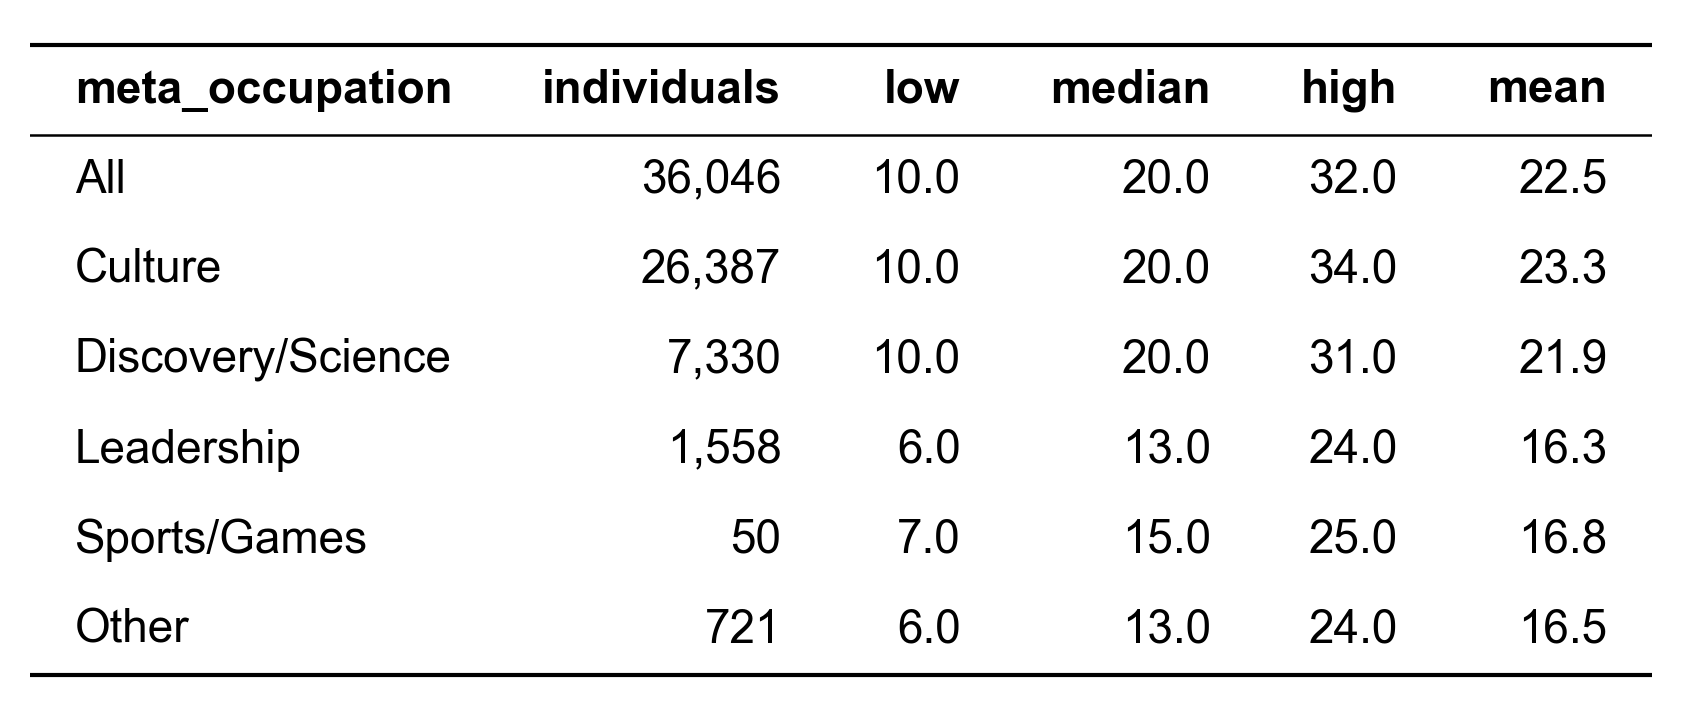

In [7]:
GROUPS = ['All', *OCCUPATION_COLORS, 'Other']
GROUP_COLORS = {'All': MAIN_LINE_COLOR, **OCCUPATION_COLORS, 'Other': GREY}
MEASURES = {
    'first_age': 'Age at first work (years)',
    'last_age': 'Age at last work (years)',
    'span': 'Length of activity (years)',
}


def box_stats(frame, column, by):
    return (
        frame.group_by(by)
        .agg(
            pl.len().alias('individuals'),
            pl.col(column).quantile(0.25, 'linear').alias('low'),
            pl.col(column).median().alias('median'),
            pl.col(column).quantile(0.75, 'linear').alias('high'),
            pl.col(column).mean().round(1).alias('mean'),
        )
        .sort(by)
    )


def group_stats(frame, column):
    everyone = box_stats(frame.with_columns(pl.lit('All').alias('meta_occupation')), column, 'meta_occupation')
    stats = pl.concat([everyone, box_stats(frame, column, 'meta_occupation').filter(pl.col('meta_occupation').is_in(GROUPS))])
    return stats.sort(pl.col('meta_occupation').replace_strict(GROUPS, list(range(len(GROUPS)))))


activity_stats = group_stats(activity, 'span')
show_table(activity_stats, decimals=1)

In [8]:
def period_label(start, width):
    end = min(start + width - 1, LAST_YEAR)
    return f'{-start}–{-end} BC' if end < 0 else f'{start}–{end}'


def draw_boxes(ax, values, positions, width, color, stats, mean_labels=True):
    ax.boxplot(values, positions=positions, widths=width, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=color, alpha=BAND_ALPHA, edgecolor=color),
               medianprops=dict(color=color, linewidth=2), whiskerprops=dict(color=color), capprops=dict(color=color))
    for x, row in zip(positions, stats.iter_rows(named=True)):
        ax.annotate(f"{row['median']:.0f}", (x + width * 0.55, row['median']), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE, color=color)
        for q in (row['low'], row['high']):
            ax.annotate(f'{q:.0f}', (x + width * 0.55, q), ha='left', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)
        ax.plot(x, row['mean'], marker='D', markersize=5, color='white', markeredgecolor=TEXT, zorder=3)
        if mean_labels:
            ax.annotate(f"{row['mean']:.1f}", (x - width * 0.55, row['mean']), ha='right', va='center', fontsize=POINT_LABEL_FONTSIZE - 2, color=TEXT)


def plot_periods(ax, frame, column, by, width, color, counts_on_top=False):
    stats = box_stats(frame, column, by).filter(pl.col('individuals') >= MIN_INDIVIDUALS)
    starts = stats[by].to_list()
    x = np.array(starts) + width / 2
    values = [frame.filter(pl.col(by) == start)[column].to_numpy() for start in starts]
    draw_boxes(ax, values, x, width * 0.5, color, stats, mean_labels=not counts_on_top)
    ax.set_xticks(x)
    labels = [period_label(start, width) for start in starts]
    if not counts_on_top:
        labels = [f'{label}\n(n = {n:,})' for label, n in zip(labels, stats['individuals'])]
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_xlim(starts[0] - width / 2, starts[-1] + 1.5 * width)
    ax.set_ylim(0, AGE_MAX)
    ax.grid(axis='y')
    if counts_on_top:
        ax.set_ylim(0, AGE_MAX + 25)
        ax.set_yticks(range(0, AGE_MAX + 1, 20))
        for xi, n in zip(x, stats['individuals']):
            ax.text(xi, AGE_MAX + 3, f'{n:,}', rotation=90, ha='center', va='bottom', fontsize=POINT_LABEL_FONTSIZE - 2, color=MUTED_TEXT)


def figure_groups(frame, column):
    stats = group_stats(frame, column)
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for i, row in enumerate(stats.iter_rows(named=True)):
        group = row['meta_occupation']
        values = frame if group == 'All' else frame.filter(pl.col('meta_occupation') == group)
        draw_boxes(ax, [values[column].to_numpy()], [i], 0.5, GROUP_COLORS[group], stats[i])
    ax.set_xticks(range(stats.height))
    ax.set_xticklabels([f"{row['meta_occupation']}\n(n = {row['individuals']:,})" for row in stats.iter_rows(named=True)])
    ax.set_xlim(-0.7, stats.height - 0.3)
    ax.set_ylim(0, AGE_MAX)
    ax.set_ylabel(MEASURES[column])
    ax.grid(axis='y')
    plt.tight_layout()
    plt.show()


def figure_periods(frame, column, by, width, xlabel, counts_on_top=False, figsize=FIGSIZE_WIDE):
    fig, ax = plt.subplots(figsize=figsize)
    plot_periods(ax, frame, column, by, width, MAIN_LINE_COLOR, counts_on_top)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(MEASURES[column])
    plt.tight_layout()
    plt.show()


def figure_occupation_periods(frame, column):
    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_GRID, sharey=True)
    for ax, (occupation, color) in zip(axes.flat, OCCUPATION_COLORS.items()):
        ax.text(0.02, 0.98, occupation, transform=ax.transAxes, fontsize=PANEL_LABEL_FONTSIZE, color=color, va='top', fontweight='bold')
        plot_periods(ax, frame.filter(pl.col('meta_occupation') == occupation), column, 'birth_period', PERIOD_WIDTH, color, counts_on_top=True)
    for ax in axes[-1, :]:
        ax.set_xlabel('Birth period')
    for ax in axes[:, 0]:
        ax.set_ylabel(MEASURES[column])
    plt.tight_layout()
    plt.show()

### Figure: length of activity, all individuals and by meta occupation
Median in colour, quartiles in grey, mean as a diamond with its value on the left.

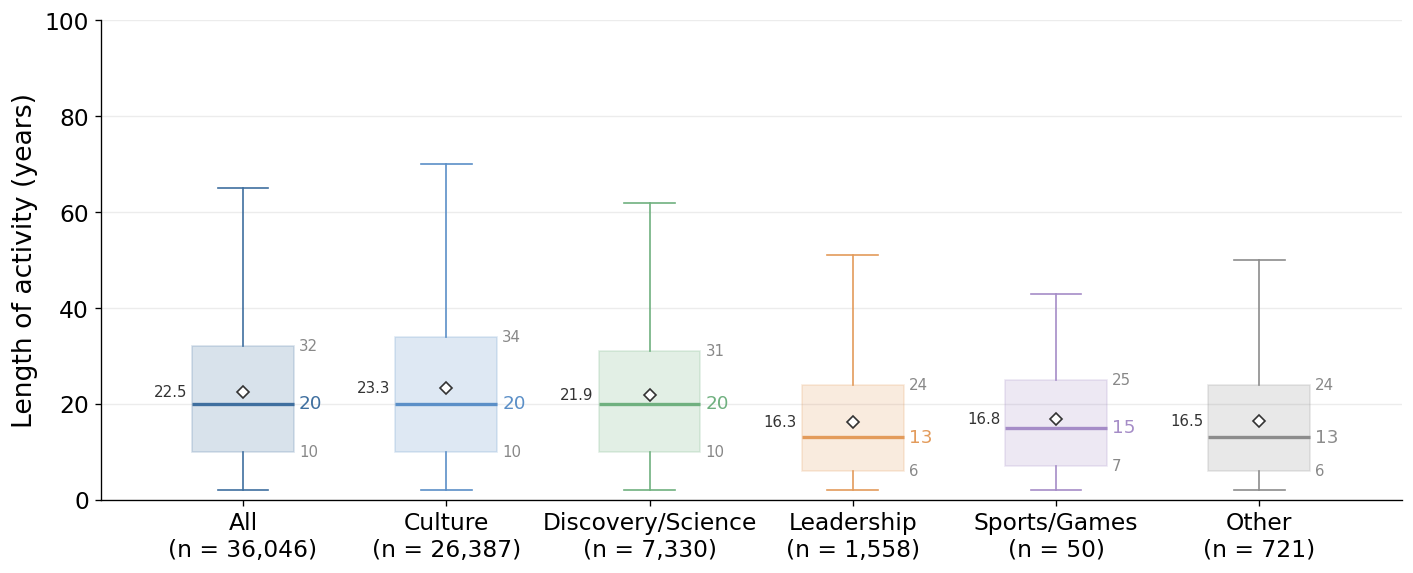

In [9]:
figure_groups(activity, 'span')

### Figure: length of activity per century of the first work
Median in colour, quartiles in grey, mean as a diamond (values in the table), individuals at the top.

In [10]:
century_stats = box_stats(activity, 'span', 'century')
print(f"{century_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} centuries with fewer than {MIN_INDIVIDUALS} individuals left out")
century_stats

7 centuries with fewer than 5 individuals left out


century,individuals,low,median,high,mean
i64,u32,f64,f64,f64,f64
-600,12,4.0,12.5,21.0,15.7
-500,28,10.0,15.0,21.5,19.0
-400,12,10.75,24.5,40.0,24.3
-300,1,21.0,21.0,21.0,21.0
-200,1,30.0,30.0,30.0,30.0
-100,8,9.75,11.0,21.75,15.6
0,3,3.5,4.0,5.5,4.7
100,4,13.75,20.5,26.5,19.8
200,2,9.5,14.0,18.5,14.0


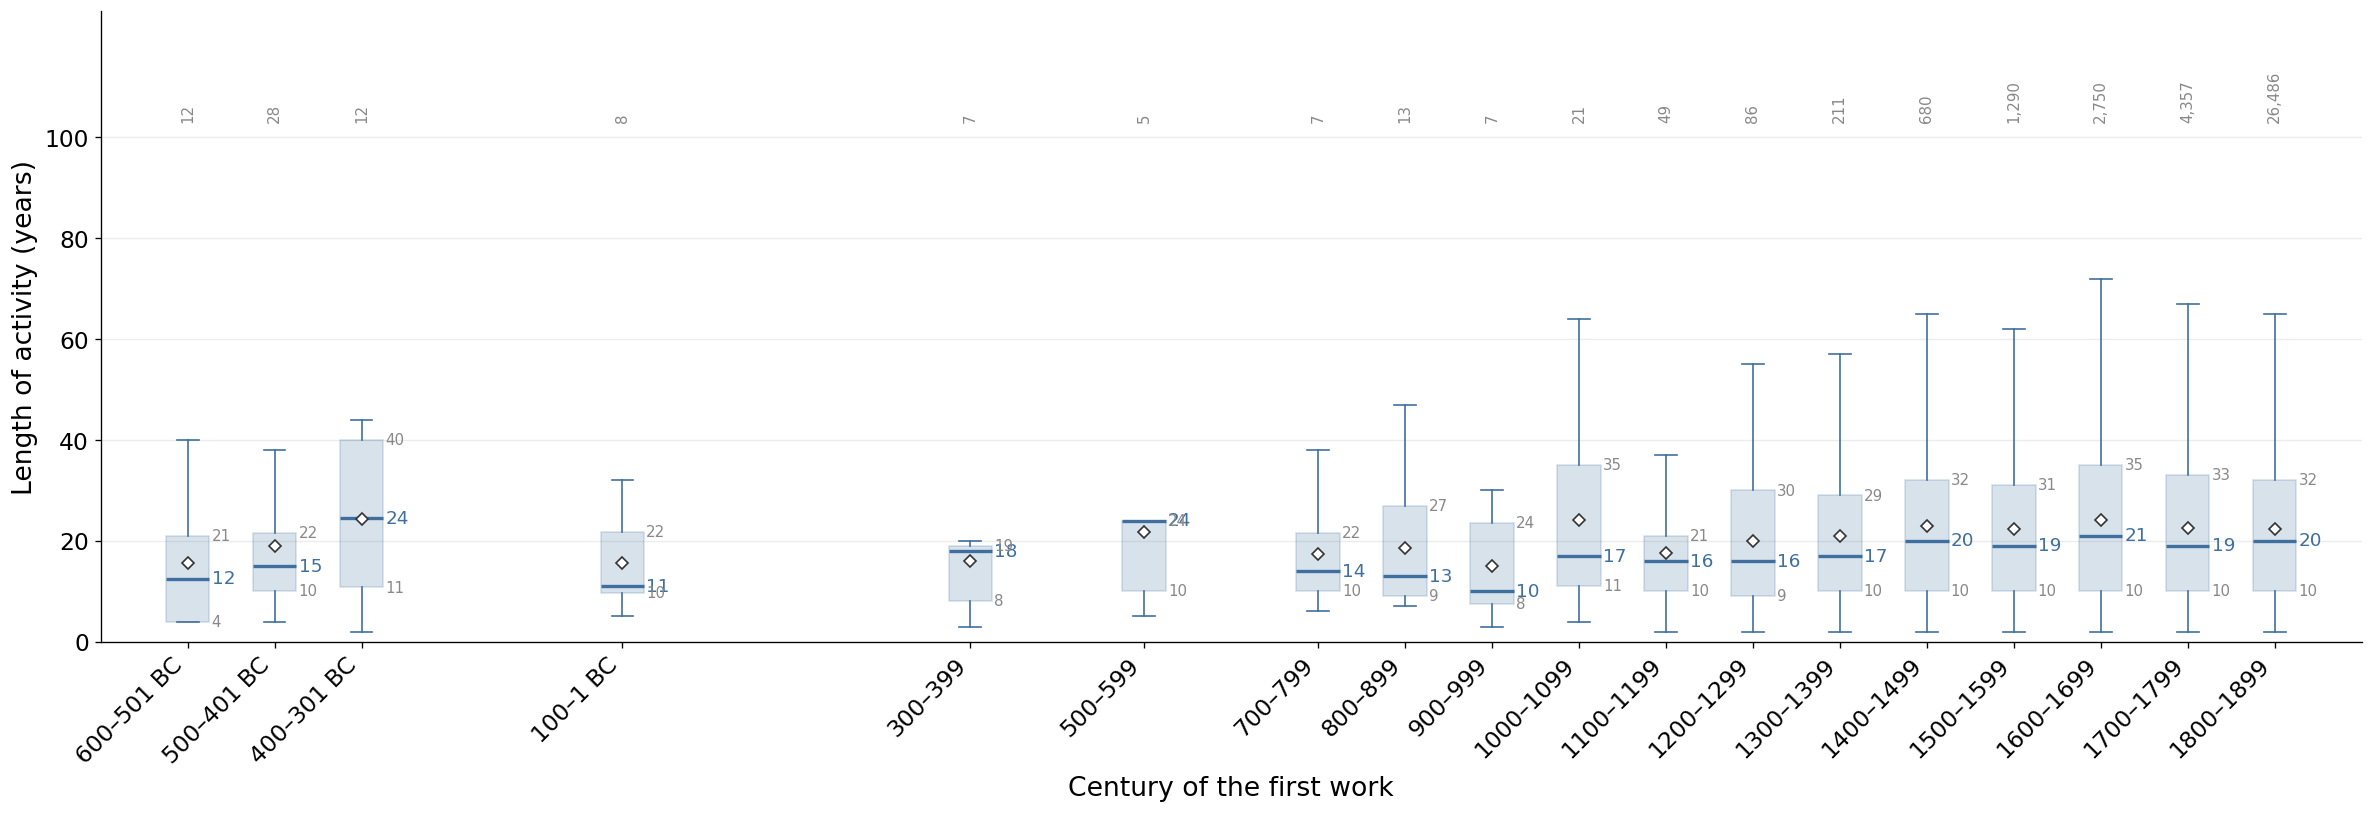

In [11]:
figure_periods(activity, 'span', 'century', CENTURY, 'Century of the first work', counts_on_top=True, figsize=(20, 7))

### Table: one example per century
The individual with the most Wikimedia pages in each century of their first work, with their first and last cleaned works. Individuals listed in `EXTRA_INDIVIDUALS` (Tycho Brahe) are added in their century.

26 centuries with an example


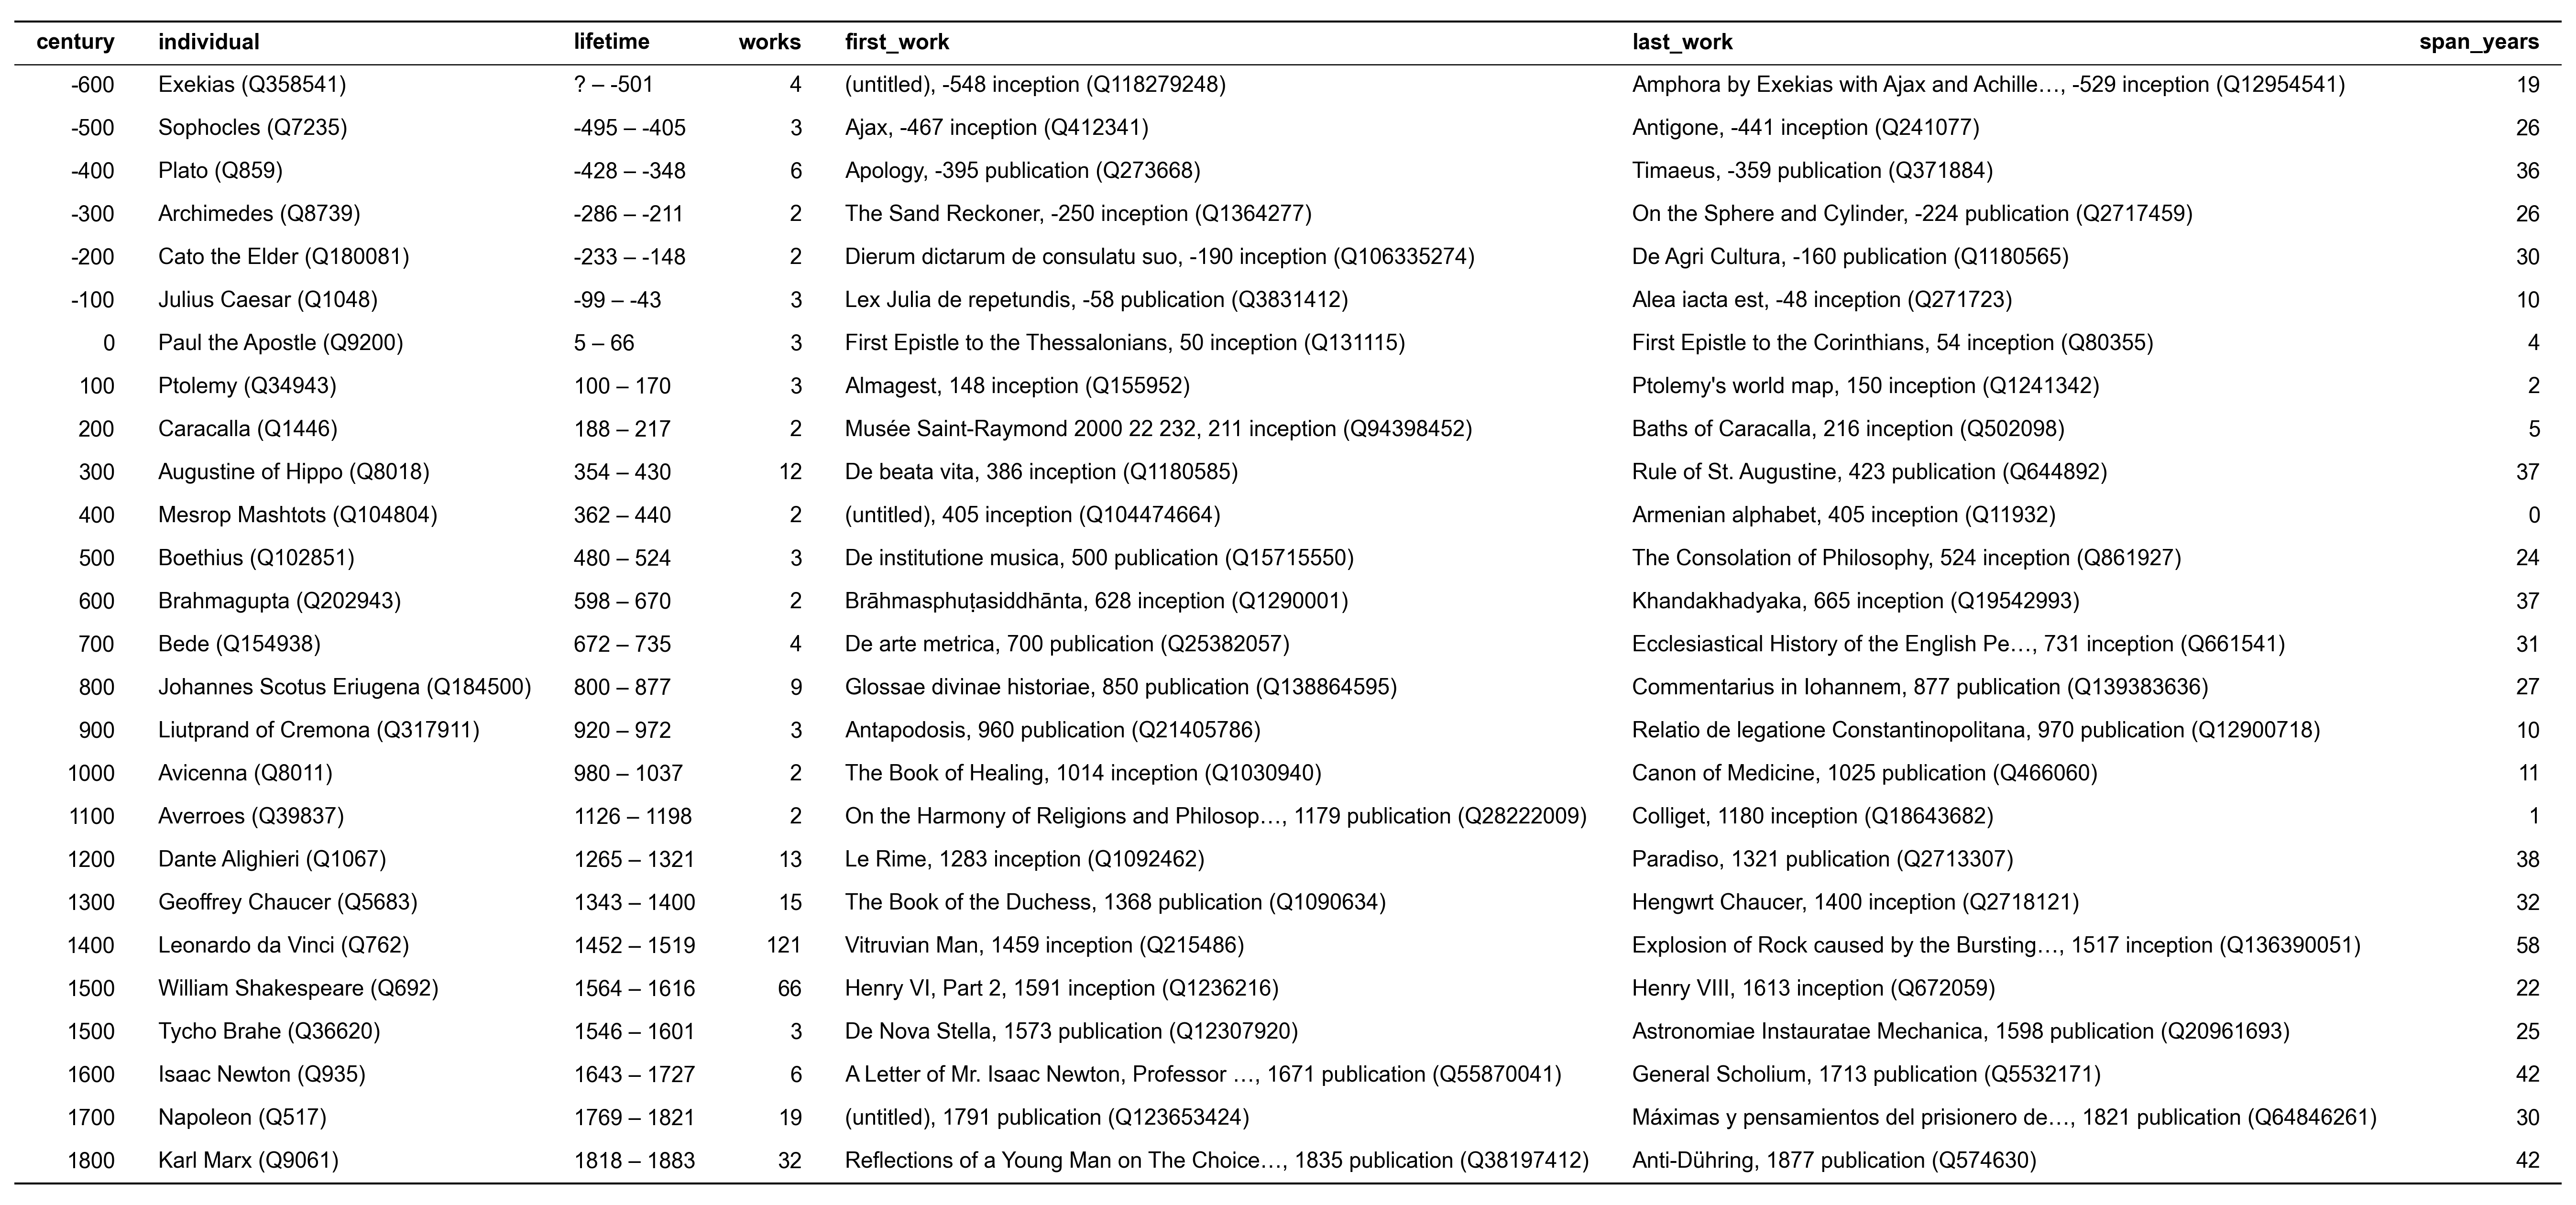

In [12]:
EXTRA_INDIVIDUALS = ['Q36620']
extra_sql = "', '".join(EXTRA_INDIVIDUALS)

connection.register('activity', activity.select('qid', 'century').to_arrow())
clean_examples = connection.execute(f'''
    WITH placed AS (
        SELECT qid, century AS century_start
        FROM activity
    ),
    best AS (
        SELECT placed.century_start, placed.qid,
               coalesce(individual.entity.label_en, individual.entity.label_non_en) || ' (' || placed.qid || ')' AS individual
        FROM placed
        JOIN individual ON individual.entity.qid = placed.qid
        WHERE placed.century_start BETWEEN {FIRST_CENTURY} AND {LAST_CENTURY}
        QUALIFY row_number() OVER (PARTITION BY placed.century_start ORDER BY len(individual.sitelink) DESC, placed.qid) = 1
              OR placed.qid IN ('{extra_sql}')
    ),
    ranked AS (
        SELECT best.century_start, best.qid, best.individual, clean_work.year,
               coalesce(clean_work.birth_year::VARCHAR, '?') || ' – ' || coalesce(clean_work.death_year::VARCHAR, '?') AS lifetime,
               CASE WHEN length(coalesce(work.entity.label_en, work.entity.label_non_en, '(untitled)')) > 40
                    THEN left(coalesce(work.entity.label_en, work.entity.label_non_en), 40) || '…'
                    ELSE coalesce(work.entity.label_en, work.entity.label_non_en, '(untitled)') END
                   || ', ' || clean_work.year || ' ' || clean_work.source || ' (' || clean_work.work_qid || ')' AS work,
               row_number() OVER (PARTITION BY best.qid ORDER BY clean_work.year, clean_work.work_qid) AS from_first,
               row_number() OVER (PARTITION BY best.qid ORDER BY clean_work.year DESC, clean_work.work_qid DESC) AS from_last,
               count(*) OVER (PARTITION BY best.qid) AS clean_works
        FROM best
        JOIN clean_work ON clean_work.qid = best.qid
        JOIN work ON work.entity.qid = clean_work.work_qid
    )
    SELECT century_start AS century, qid, individual, max(lifetime) AS lifetime, max(clean_works) AS works,
           max(work) FILTER (WHERE from_first = 1) AS first_work,
           max(work) FILTER (WHERE from_last = 1 AND clean_works > 1) AS last_work,
           max(year) FILTER (WHERE from_last = 1) - max(year) FILTER (WHERE from_first = 1) AS span_years
    FROM ranked
    GROUP BY century_start, qid, individual
    ORDER BY century_start, qid IN ('{extra_sql}'), individual
''').pl().with_columns(pl.col('century').cast(pl.String)).drop('qid')
print(f'{clean_examples.height} centuries with an example')
show_table(clean_examples)

## 2. "fl." in the description against the works
Individuals with both a two-date "fl." and at least two works. Does the "fl." start agree with the first work, its end with the last work, and its length with the length of activity? The works are taken twice: cleaned (section "Load the data"), and all works dated to the year or decade before cleaning (publication, else inception), since the cleaning drops most individuals without birth or death, who are those described by a "fl.".

68 individuals with a two-date "fl." and at least 2 cleaned works
91 individuals with a two-date "fl." and at least 2 all precise works


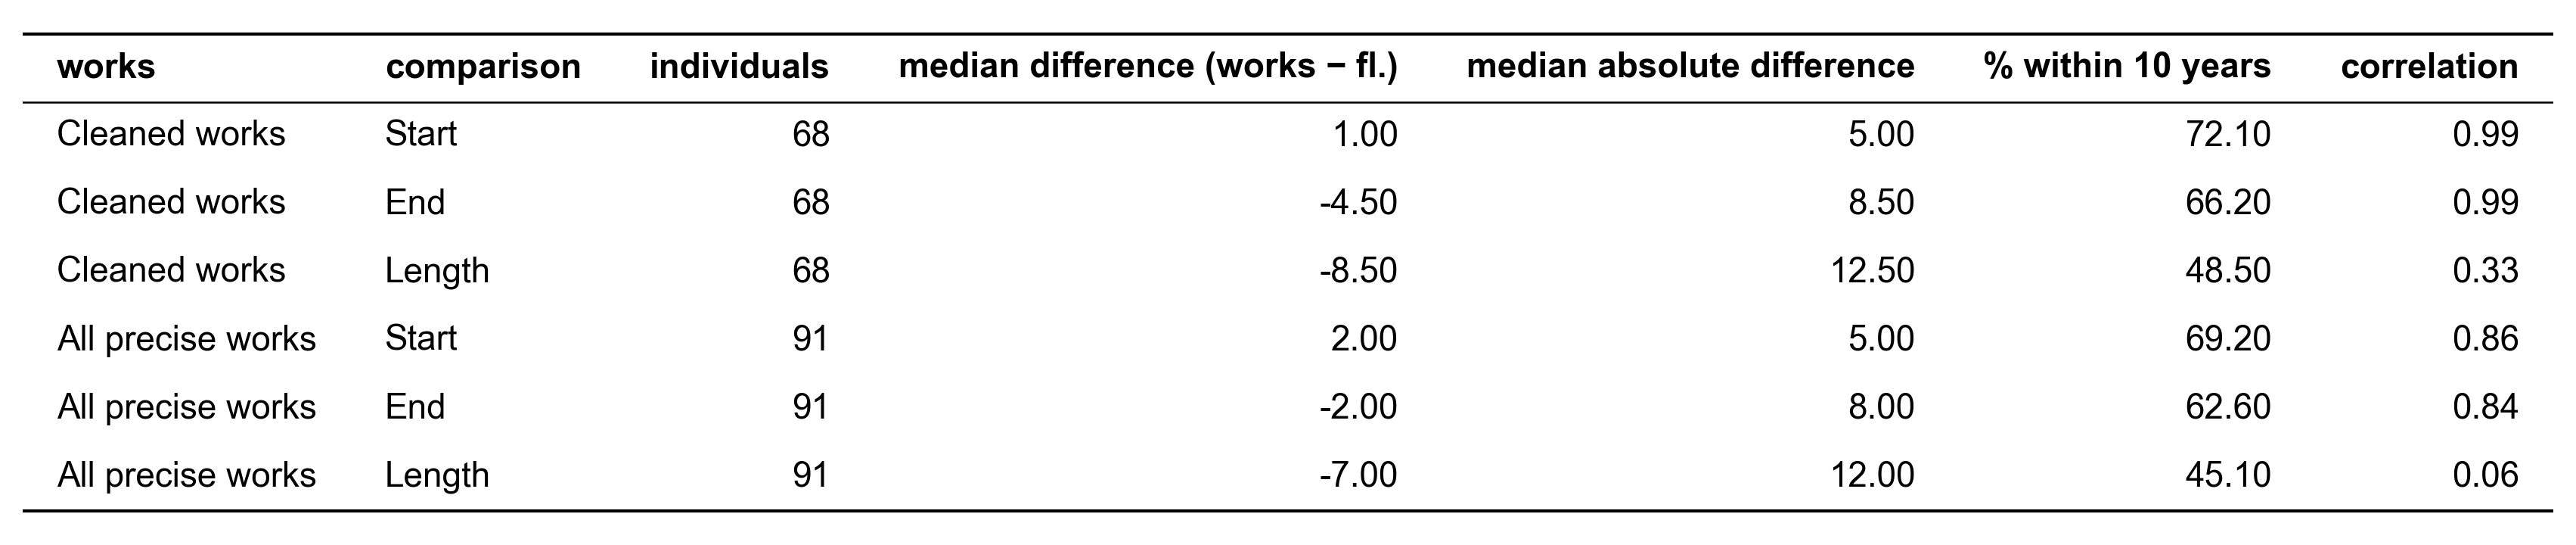

In [13]:
WITHIN = 10
WORK_SETS = {
    'Cleaned works': periods.filter(pl.col('works') >= 2).select('qid', 'first_year', 'last_year', 'span'),
    'All precise works': works.filter(pl.col('precise_works') >= 2).select(
        'qid', pl.col('first_precise_year').alias('first_year'), pl.col('last_precise_year').alias('last_year'),
        (pl.col('last_precise_year') - pl.col('first_precise_year')).alias('span')),
}
COMPARISONS = [('Start', 'fl_start', 'first_year'), ('End', 'fl_end', 'last_year'), ('Length', 'fl_span', 'span')]

compared = {name: fl.join(frame, on='qid') for name, frame in WORK_SETS.items()}
for name, frame in compared.items():
    print(f'{frame.height:,} individuals with a two-date "fl." and at least 2 {name.lower()}')

show_table(pl.DataFrame([
    {
        'works': name,
        'comparison': label,
        'individuals': frame.height,
        'median difference (works − fl.)': (frame[work_column] - frame[fl_column]).median(),
        'median absolute difference': (frame[work_column] - frame[fl_column]).abs().median(),
        f'% within {WITHIN} years': round(100 * ((frame[work_column] - frame[fl_column]).abs() <= WITHIN).mean(), 1),
        'correlation': round(np.corrcoef(frame[work_column], frame[fl_column])[0, 1], 2),
    }
    for name, frame in compared.items() for label, fl_column, work_column in COMPARISONS
]), decimals=2)

### Figure: "fl." against the works, start, end and length
One row per set of works; each dot is an individual, the dotted line is perfect agreement.

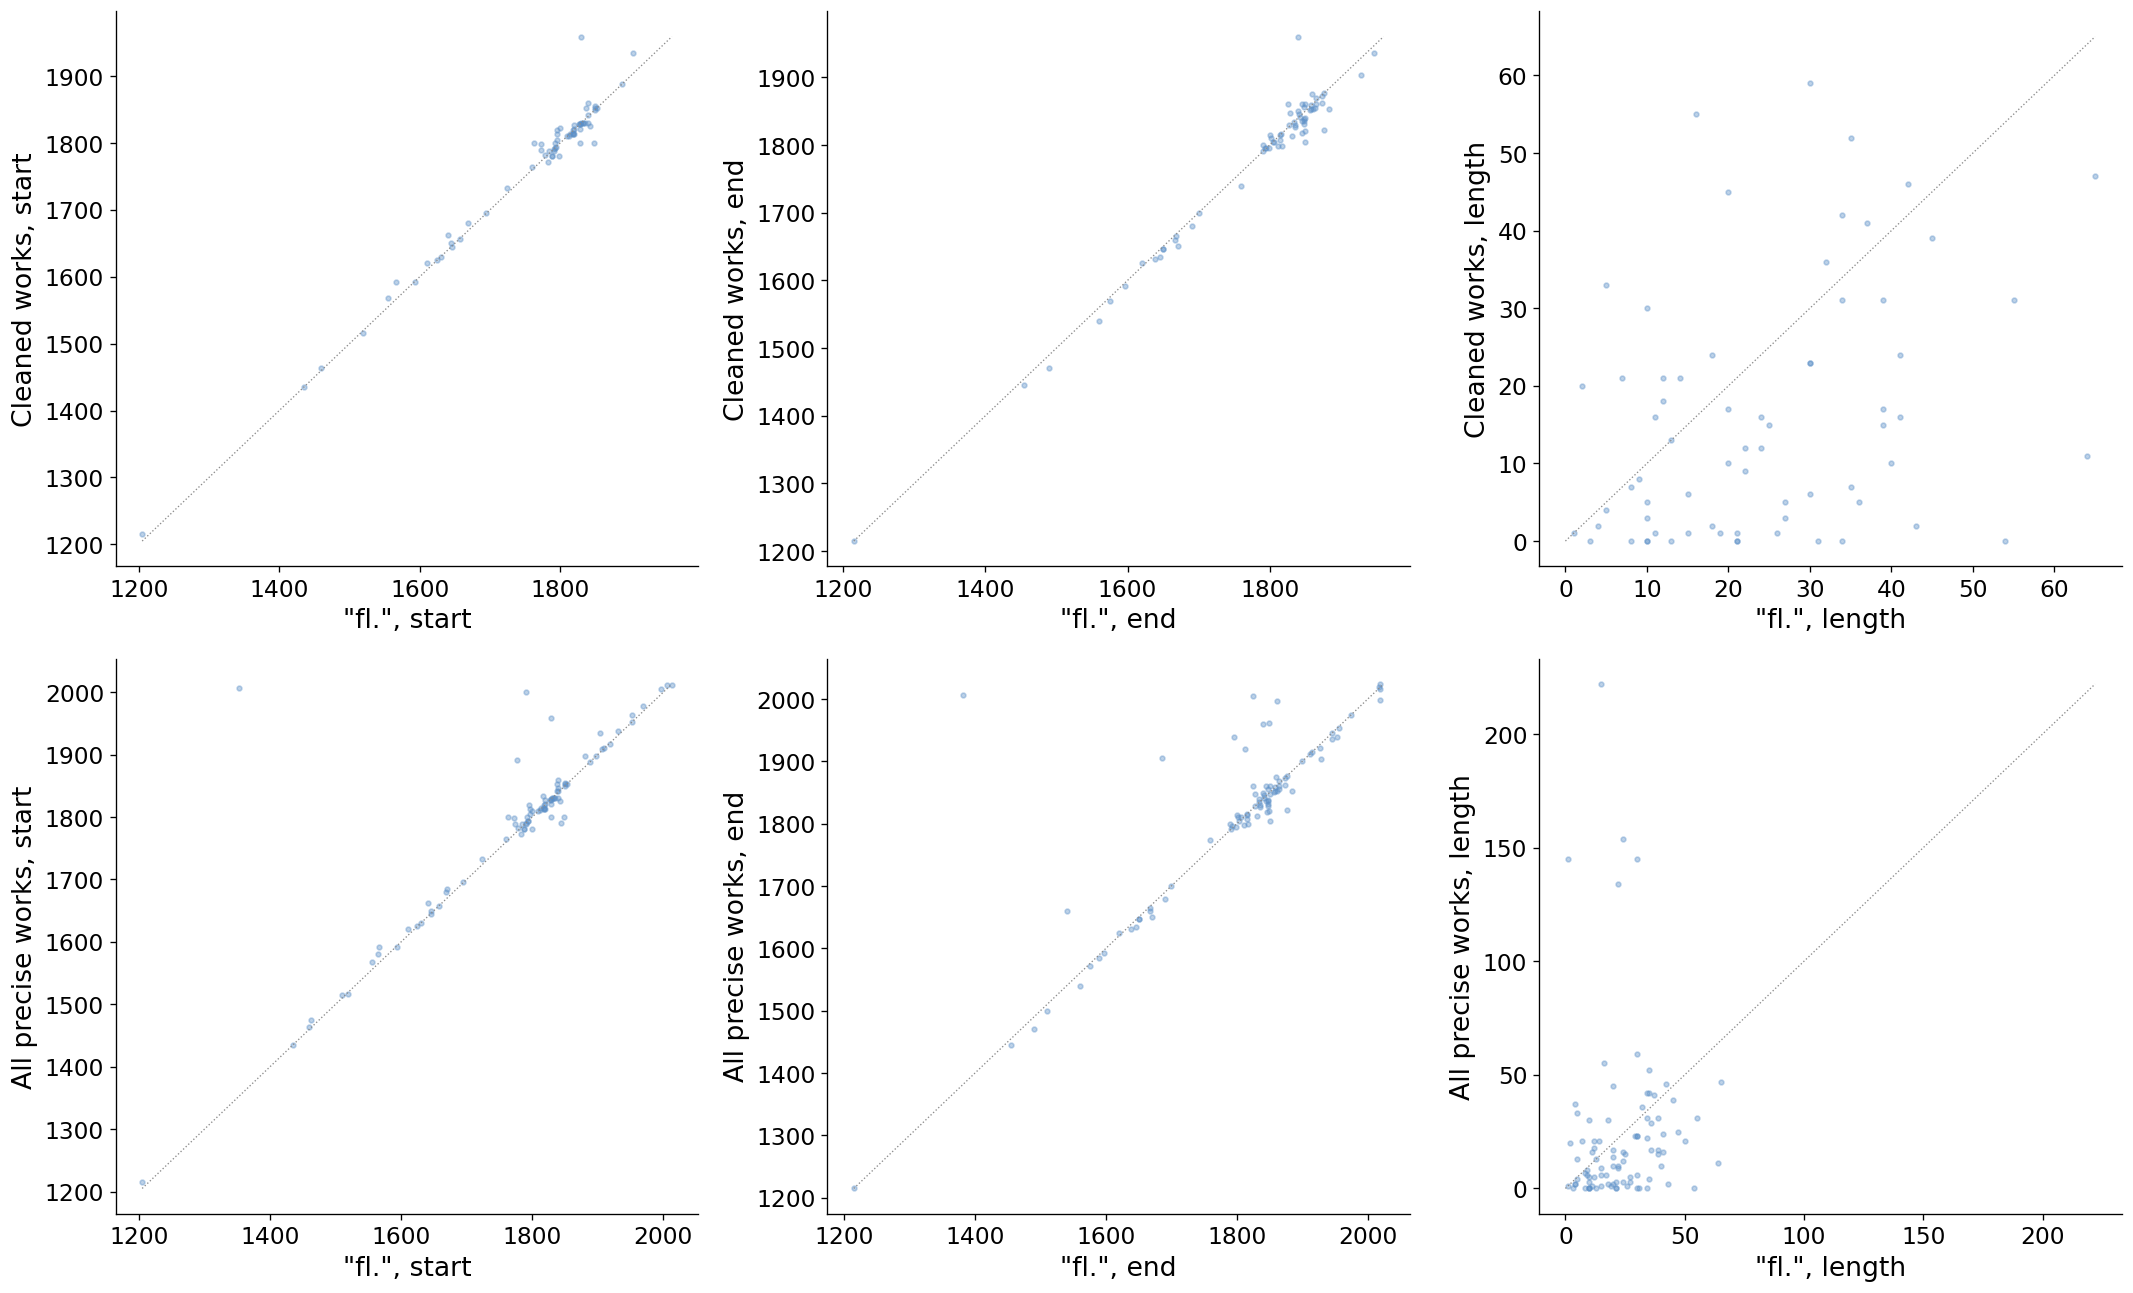

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for row, (name, frame) in zip(axes, compared.items()):
    for ax, (label, fl_column, work_column) in zip(row, COMPARISONS):
        ax.scatter(frame[fl_column], frame[work_column], s=8, alpha=0.4, color=MAIN_COLOR)
        low = min(frame[fl_column].min(), frame[work_column].min())
        high = max(frame[fl_column].max(), frame[work_column].max())
        ax.plot([low, high], [low, high], **REFERENCE_LINE)
        ax.set_xlabel(f'"fl.", {label.lower()}')
        ax.set_ylabel(f'{name}, {label.lower()}')
plt.tight_layout()
plt.show()

### Table: examples
The individuals with the most Wikimedia pages, with their cleaned works when they have some.

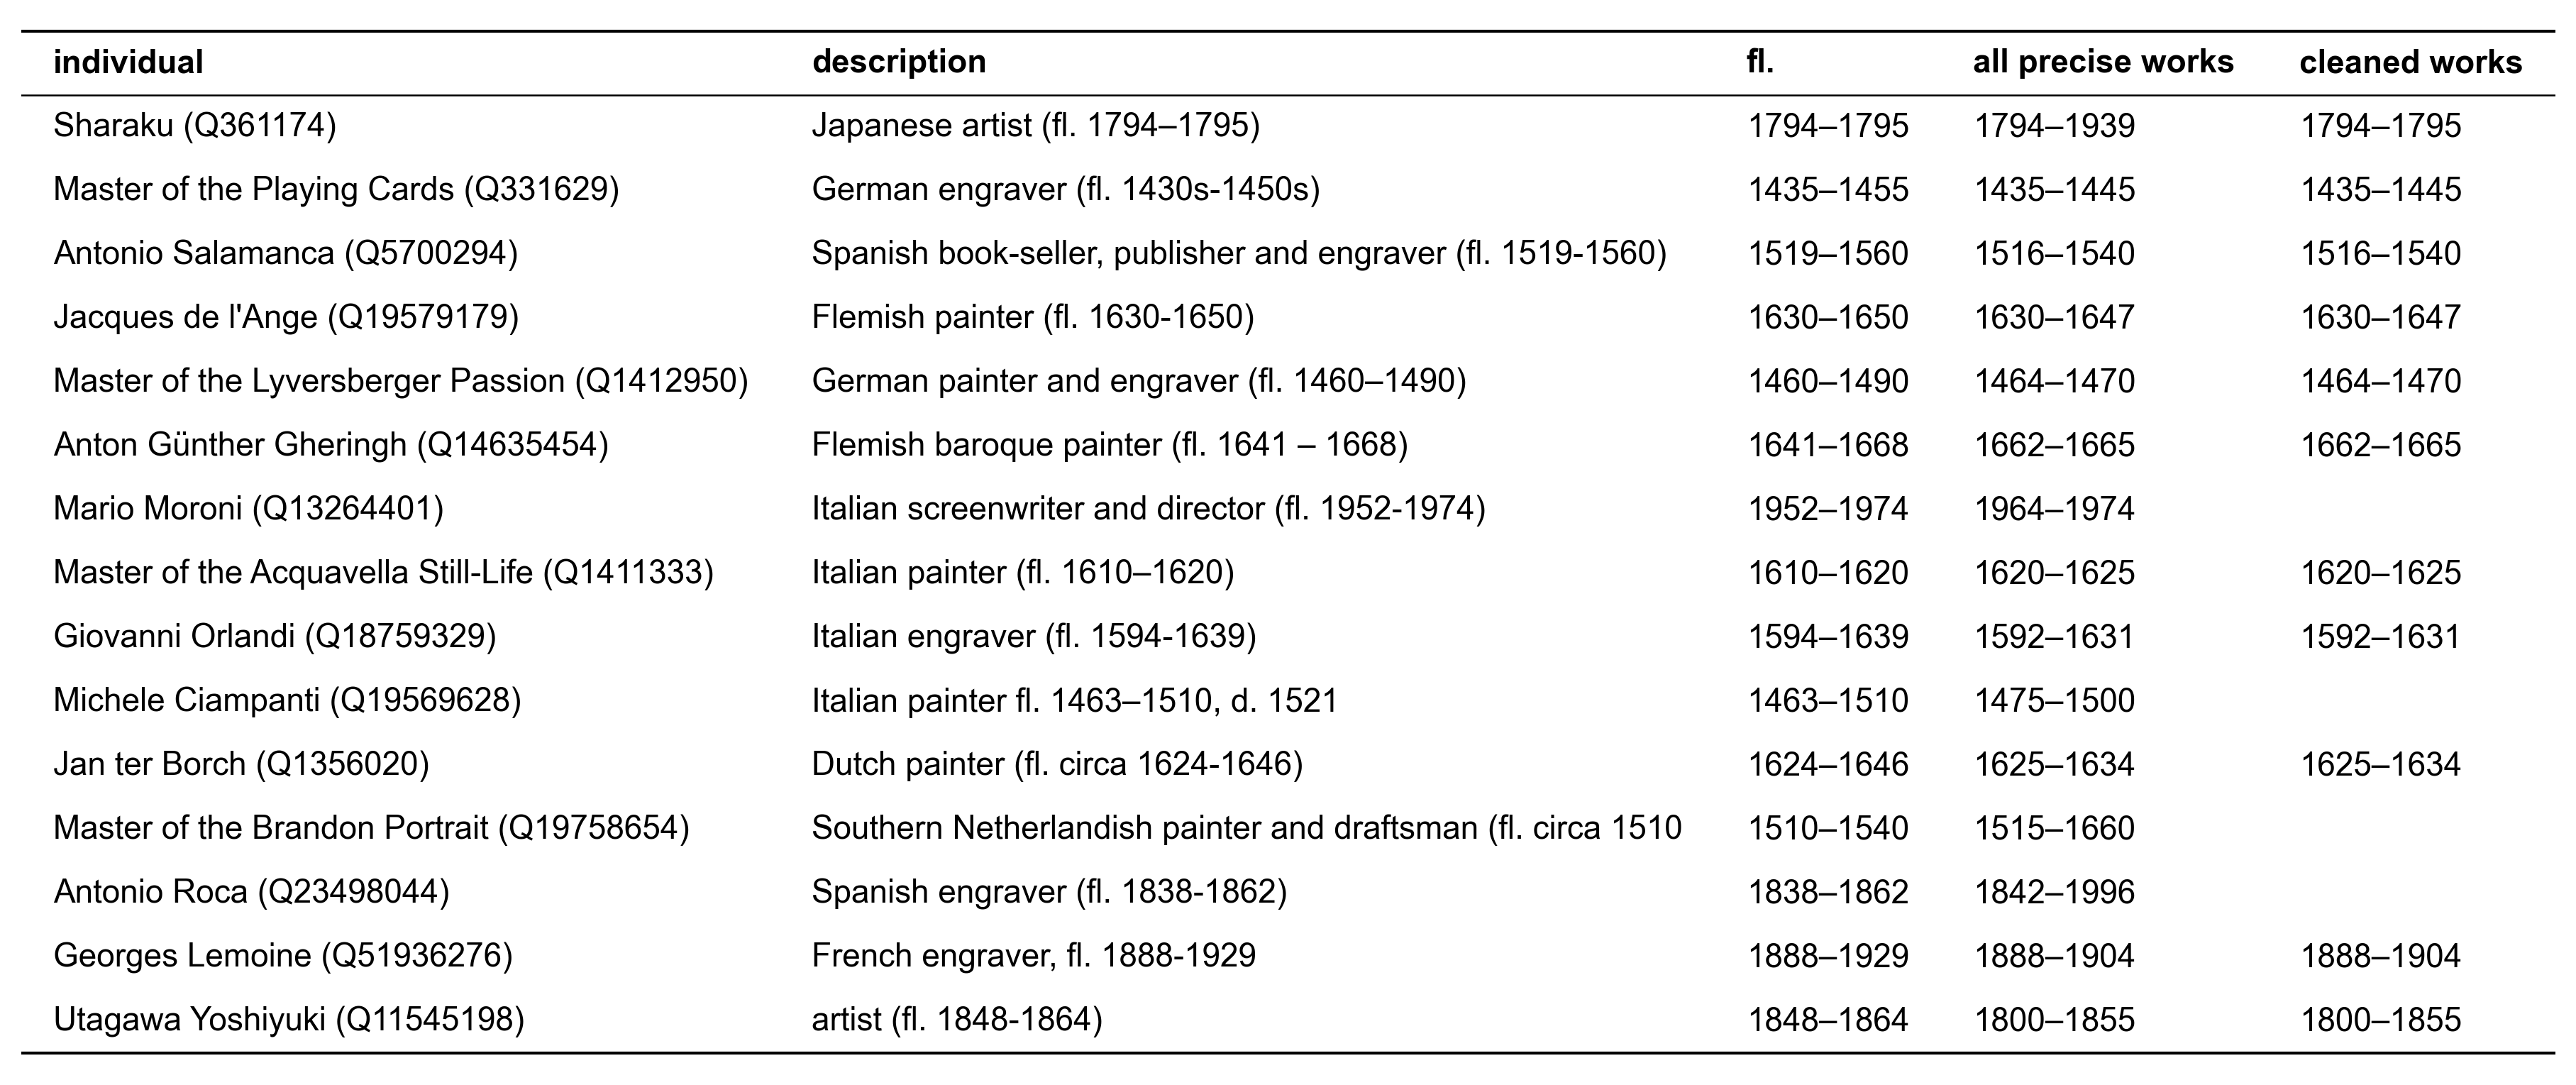

In [15]:
show_table(
    compared['All precise works']
    .join(compared['Cleaned works'].select('qid', pl.format('{}–{}', 'first_year', 'last_year').alias('cleaned works')), on='qid', how='left')
    .sort('sitelinks', 'qid', descending=[True, False]).head(15)
    .select(
        pl.format('{} ({})', 'name', 'qid').alias('individual'),
        pl.col('description').str.slice(0, 60),
        pl.format('{}–{}', 'fl_start', 'fl_end').alias('fl.'),
        pl.format('{}–{}', 'first_year', 'last_year').alias('all precise works'),
        pl.col('cleaned works').fill_null(''),
    )
)

## 3. Which model best estimates the length of activity?
As for life expectancy (notebook 01): a random 80% of the group learns the mean length of activity (train); for the other 20% (test), the last work is estimated as first work + that mean, and is good when within 10 years of the true last work. A group with fewer than 10 training individuals takes the global mean. The century is the century of the first work. Models:

- **random**: a length drawn at random between 0 and 40 years.
- **global**: all training individuals.
- **century**, **meta occupation**, **century × meta occupation**: the training individuals of the same group.

In [16]:
SEED = 42
TRAIN_SHARE = 0.8
MIN_TRAIN = 10
RANDOM_SPAN = 40
MODELS = {'century': ['century'], 'meta occupation': ['meta_occupation'], 'century × meta occupation': ['century', 'meta_occupation']}
MODEL_COLORS = {'random': LIGHT_GREY, 'global': GREY, 'century': BLUE, 'meta occupation': ORANGE, 'century × meta occupation': GREEN}

shuffled = activity.sort('qid').sample(fraction=1, shuffle=True, seed=SEED)
cut = int(TRAIN_SHARE * shuffled.height)
train, test = shuffled[:cut], shuffled[cut:]
assert train.height + test.height == activity.height and test.join(train, on='qid').height == 0
global_mean = train['span'].mean()
print(f'train: {train.height:,}, test: {test.height:,}, global mean: {global_mean:.1f} years')

base = test.select('qid', 'century', 'meta_occupation', 'first_year', 'last_year')
models = [
    base.with_columns(pl.lit('random').alias('model'), pl.Series('length', np.random.default_rng(SEED).integers(0, RANDOM_SPAN + 1, base.height)).cast(pl.Float64)),
    base.with_columns(pl.lit('global').alias('model'), pl.lit(global_mean).alias('length')),
]
for model, keys in MODELS.items():
    means = train.group_by(keys).agg(pl.len().alias('train individuals'), pl.col('span').mean().alias('length')).filter(pl.col('train individuals') >= MIN_TRAIN)
    joined = base.join(means, on=keys, how='left')
    print(f"{model}: {joined['length'].null_count():,} test individuals take the global mean")
    models.append(joined.select(*base.columns, pl.lit(model).alias('model'), pl.col('length').fill_null(global_mean)))
estimated = pl.concat(models).with_columns(
    (pl.col('first_year') + pl.col('length').round()).cast(pl.Int64).alias('estimated last year'),
).with_columns((pl.col('estimated last year') - pl.col('last_year')).alias('error'))
estimated.sample(5, seed=SEED)

train: 28,836, test: 7,210, global mean: 22.5 years
century: 13 test individuals take the global mean
meta occupation: 0 test individuals take the global mean
century × meta occupation: 41 test individuals take the global mean


qid,century,meta_occupation,first_year,last_year,model,length,estimated last year,error
str,i64,str,i64,i64,str,f64,i64,i64
"""Q18507949""",1600,"""Culture""",1655,1664,"""century × meta occupation""",24.924501,1680,16
"""Q570279""",1800,"""Culture""",1847,1852,"""global""",22.526945,1870,18
"""Q62114922""",1700,"""Culture""",1776,1780,"""century × meta occupation""",23.436006,1799,19
"""Q2253952""",1500,"""Culture""",1598,1623,"""meta occupation""",23.268607,1621,-2
"""Q28651632""",1800,"""Other""",1897,1934,"""meta occupation""",16.451389,1913,-21


### Accuracy
Each score is computed in every century of the first work (with at least 10 test individuals), then averaged with every century weighing the same.

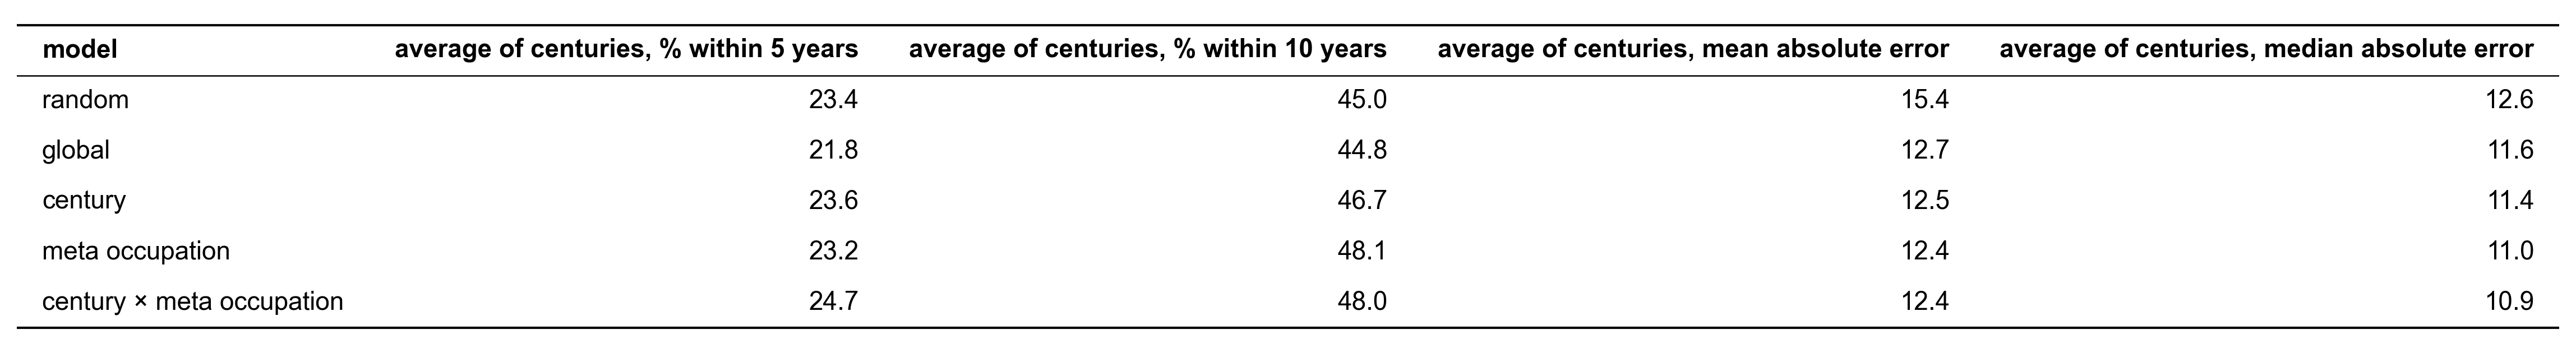

In [17]:
per_century = (
    estimated.group_by('model', 'century', maintain_order=True).agg(
        pl.len().alias('individuals'),
        *[(100 * (pl.col('error').abs() <= years).mean()).alias(f'% within {years} years') for years in (5, WITHIN)],
        pl.col('error').abs().mean().alias('mean absolute error'),
        pl.col('error').abs().median().alias('median absolute error'),
    )
    .filter(pl.col('individuals') >= MIN_TRAIN)
    .sort('century')
)
model_result = (
    per_century.group_by('model')
    .agg(pl.col('% within 5 years', f'% within {WITHIN} years', 'mean absolute error', 'median absolute error').mean().name.prefix('average of centuries, '))
    .sort(pl.col('model').replace_strict(list(MODEL_COLORS), list(range(len(MODEL_COLORS)))))
)
show_table(model_result, decimals=1)

### Figure: % of last works within 10 years per century of the first work
Number of test individuals above each century.

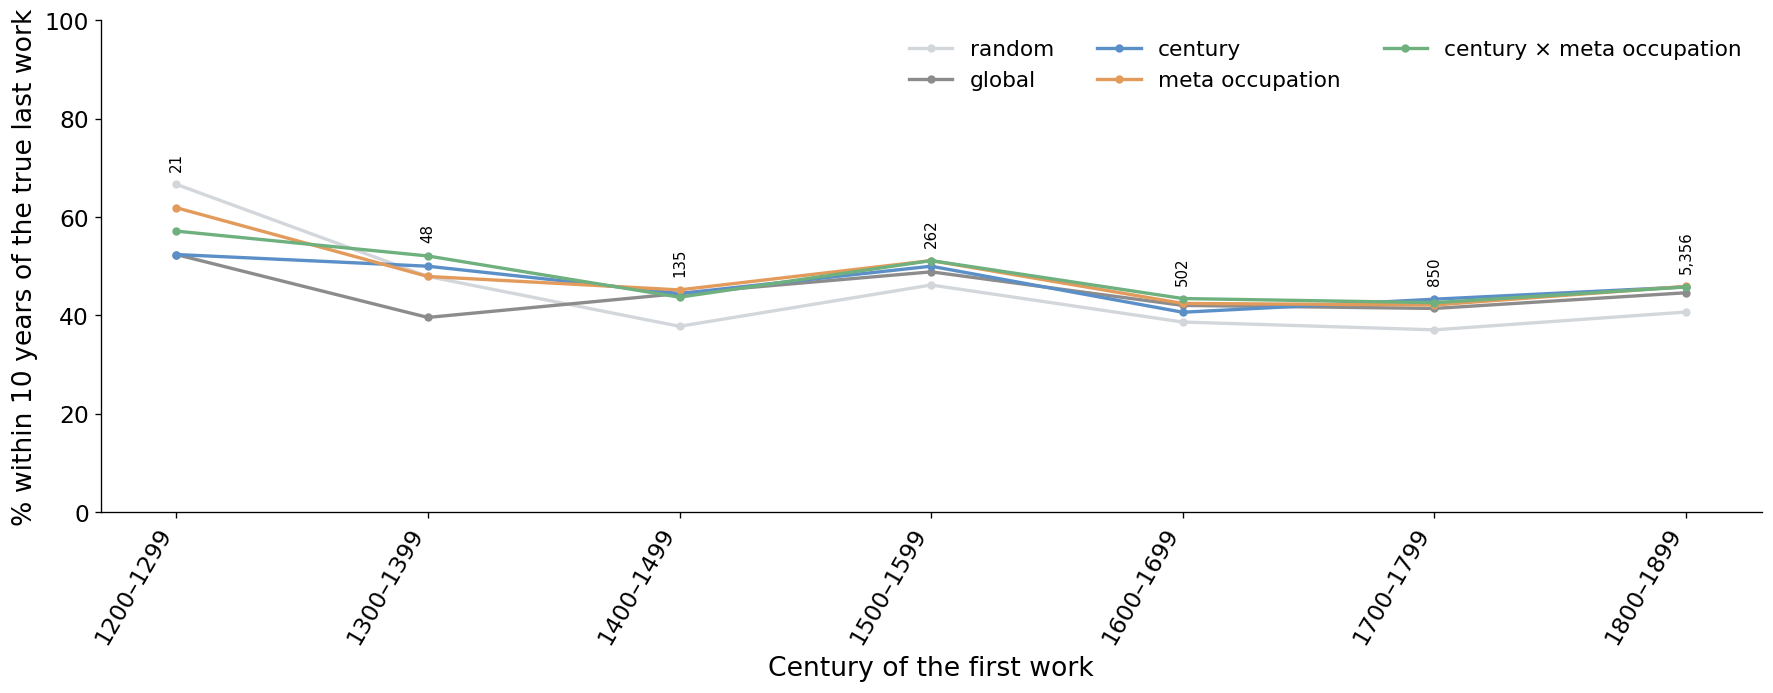

In [18]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for model, color in MODEL_COLORS.items():
    rows = per_century.filter(pl.col('model') == model)
    ax.plot(rows['century'], rows[f'% within {WITHIN} years'], color=color, linewidth=2, marker='o', markersize=4, label=model)
tested = per_century.group_by('century').agg(pl.col('individuals').first(), pl.col(f'% within {WITHIN} years').max()).sort('century')
for century, tested_individuals, top in tested.iter_rows():
    ax.annotate(f'{tested_individuals:,}', (century, top), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, rotation=90, va='bottom')
ax.set_xticks(tested['century'].to_list())
ax.set_xticklabels([period_label(start, CENTURY) for start in tested['century']], rotation=60, ha='right', fontsize=14)
ax.set_ylim(0, 100)
ax.set_ylabel(f'% within {WITHIN} years of the true last work')
ax.set_xlabel('Century of the first work')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right', ncols=3)
plt.tight_layout()
plt.show()

## 4. Individuals with dated works, by century
Before cleaning; each individual is placed at the century of their first work dated to the year or decade.

In [19]:
def by_century(frame, year_column):
    in_range = frame.with_columns((pl.col(year_column) // 100 * 100).alias('century_start')).filter(
        pl.col('century_start').is_between(COVERAGE_FIRST, COVERAGE_LAST))
    print(f'{frame.height - in_range.height:,} individuals outside {COVERAGE_FIRST}–{COVERAGE_LAST + 99} or without a year left out of the table')
    return in_range.group_by('century_start').len('individuals').sort('century_start')


def plot_centuries(series, labelled=()):
    fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
    for name, frame in series.items():
        frame = frame.filter(pl.col('individuals') > 0)
        ax.plot(frame['century_start'], frame['individuals'], marker='o', markersize=5, color=SERIES_COLORS[name], label=name)
        if name in labelled:
            for x, y in zip(frame['century_start'], frame['individuals']):
                ax.annotate(f'{y:,}', (x, y), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=POINT_LABEL_FONTSIZE, color=TEXT)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(THOUSANDS)
    ax.set_xlim(COVERAGE_FIRST - 50, COVERAGE_LAST + 50)
    ax.set_xticks(range(COVERAGE_FIRST, COVERAGE_LAST + 1, 100))
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    ax.set_xlabel('Century (start year)')
    ax.set_ylabel('Individuals (log scale)')
    ax.grid(axis='y')
    ax.legend(loc='upper left')
    plt.show()

In [20]:
two_precise = works.filter(pl.col('precise_works') >= 2)
one_work = works.filter(pl.col('precise_works') == 1)
print(f'{two_precise.height:,} individuals with at least 2 works dated to the year or decade, {one_work.height:,} with only 1')
two_precise_century = by_century(two_precise, 'first_precise_year')
one_work_century = by_century(one_work, 'first_precise_year')

1,789,214 individuals with at least 2 works dated to the year or decade, 984,063 with only 1


7 individuals outside -1000–2099 or without a year left out of the table
11 individuals outside -1000–2099 or without a year left out of the table


### Figure: individuals with at least 2 precise works, by century

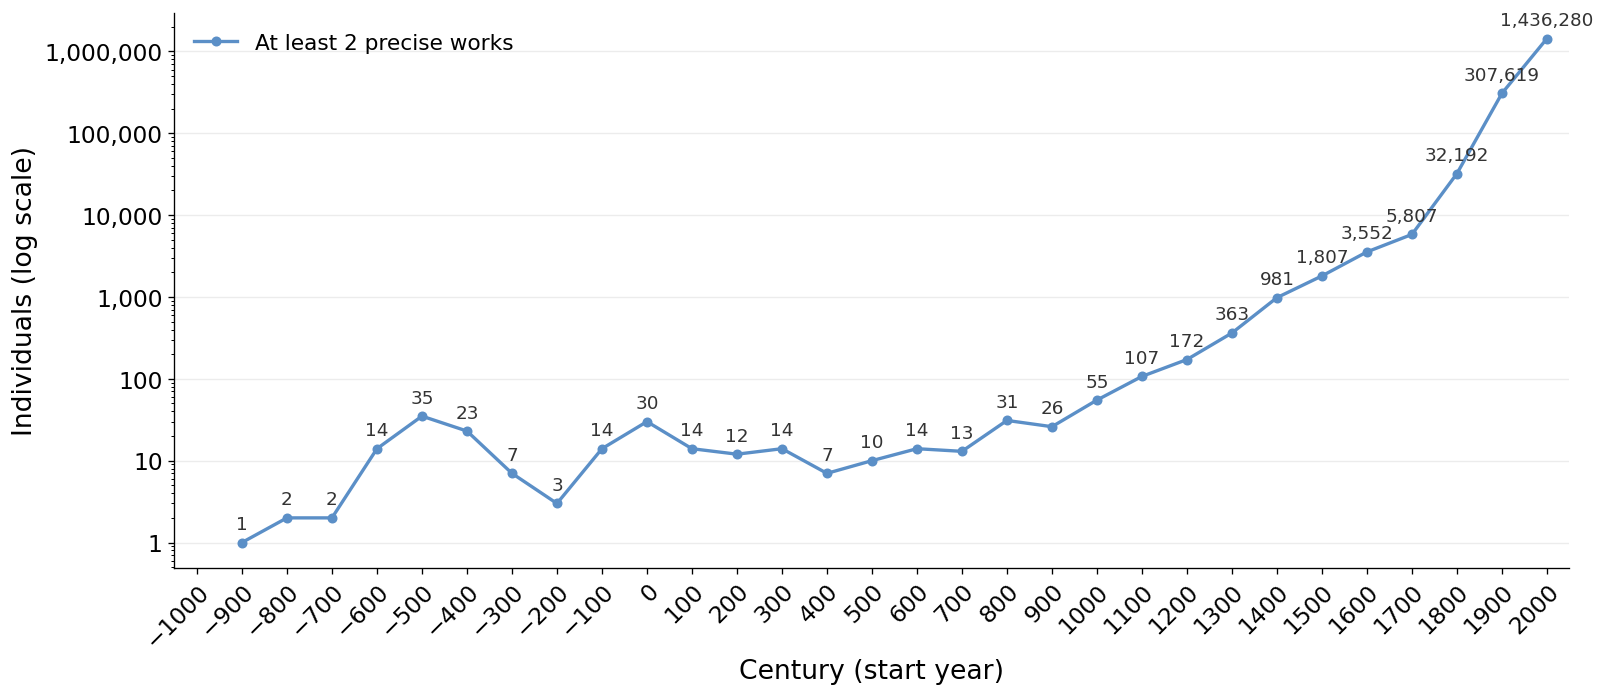

In [21]:
plot_centuries({'At least 2 precise works': two_precise_century}, labelled=['At least 2 precise works'])

### Figure: individuals with only one precise work, by century

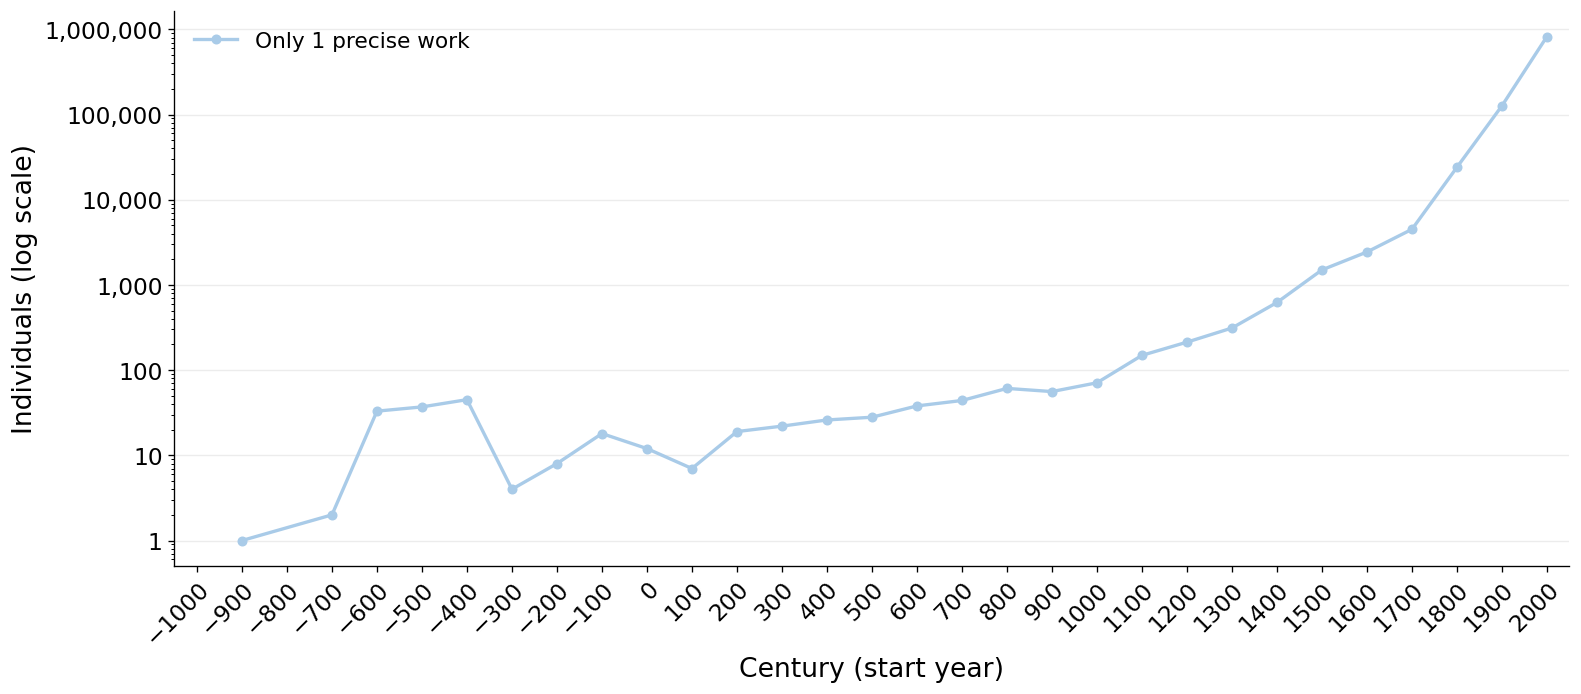

In [22]:
plot_centuries({'Only 1 precise work': one_work_century})

In [23]:
one_or_more_century = (
    two_precise_century.join(one_work_century, on='century_start', how='full', coalesce=True, suffix='_one')
    .fill_null(0)
    .select('century_start', (pl.col('individuals') + pl.col('individuals_one')).alias('individuals'))
    .sort('century_start')
)
assert one_or_more_century['individuals'].sum() == two_precise_century['individuals'].sum() + one_work_century['individuals'].sum()

### Figure: individuals with at least one work with a precise date, by century

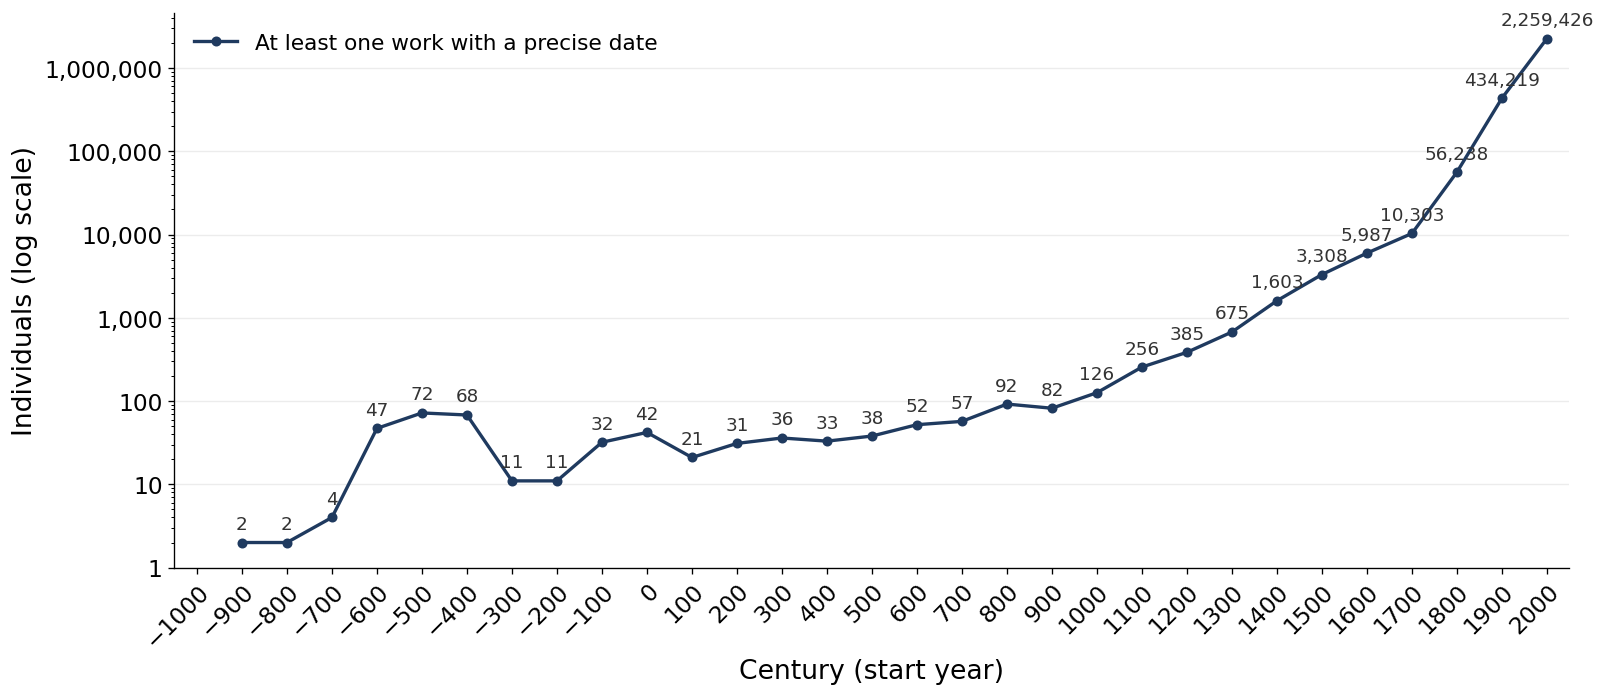

In [24]:
plot_centuries({'At least one work with a precise date': one_or_more_century}, labelled=['At least one work with a precise date'])

### Figure: individuals with dated works, by century

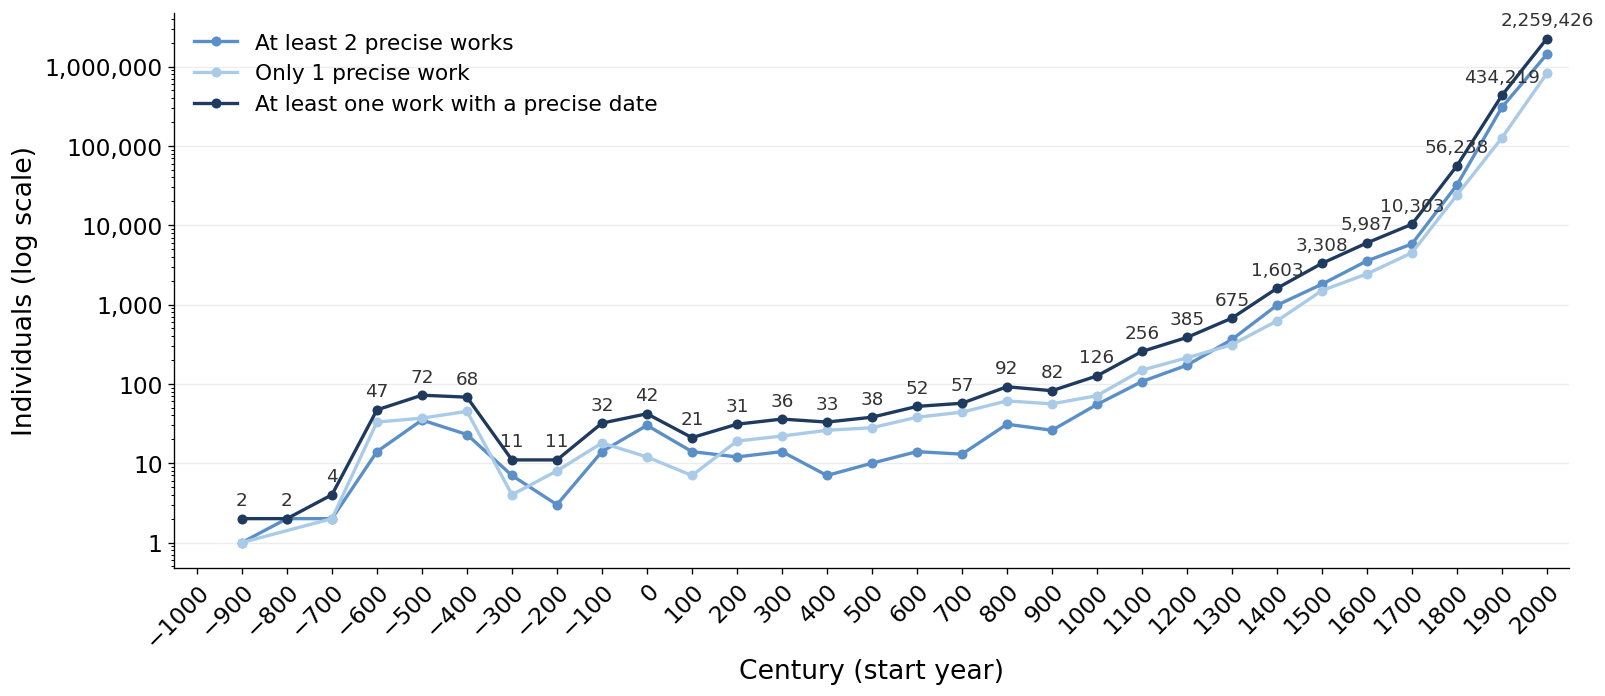

In [25]:
plot_centuries({
    'At least 2 precise works': two_precise_century,
    'Only 1 precise work': one_work_century,
    'At least one work with a precise date': one_or_more_century,
}, labelled=['At least one work with a precise date'])

### Table: individuals with dated works, by century
The total row also counts individuals placed outside 1000 BC – 2099.

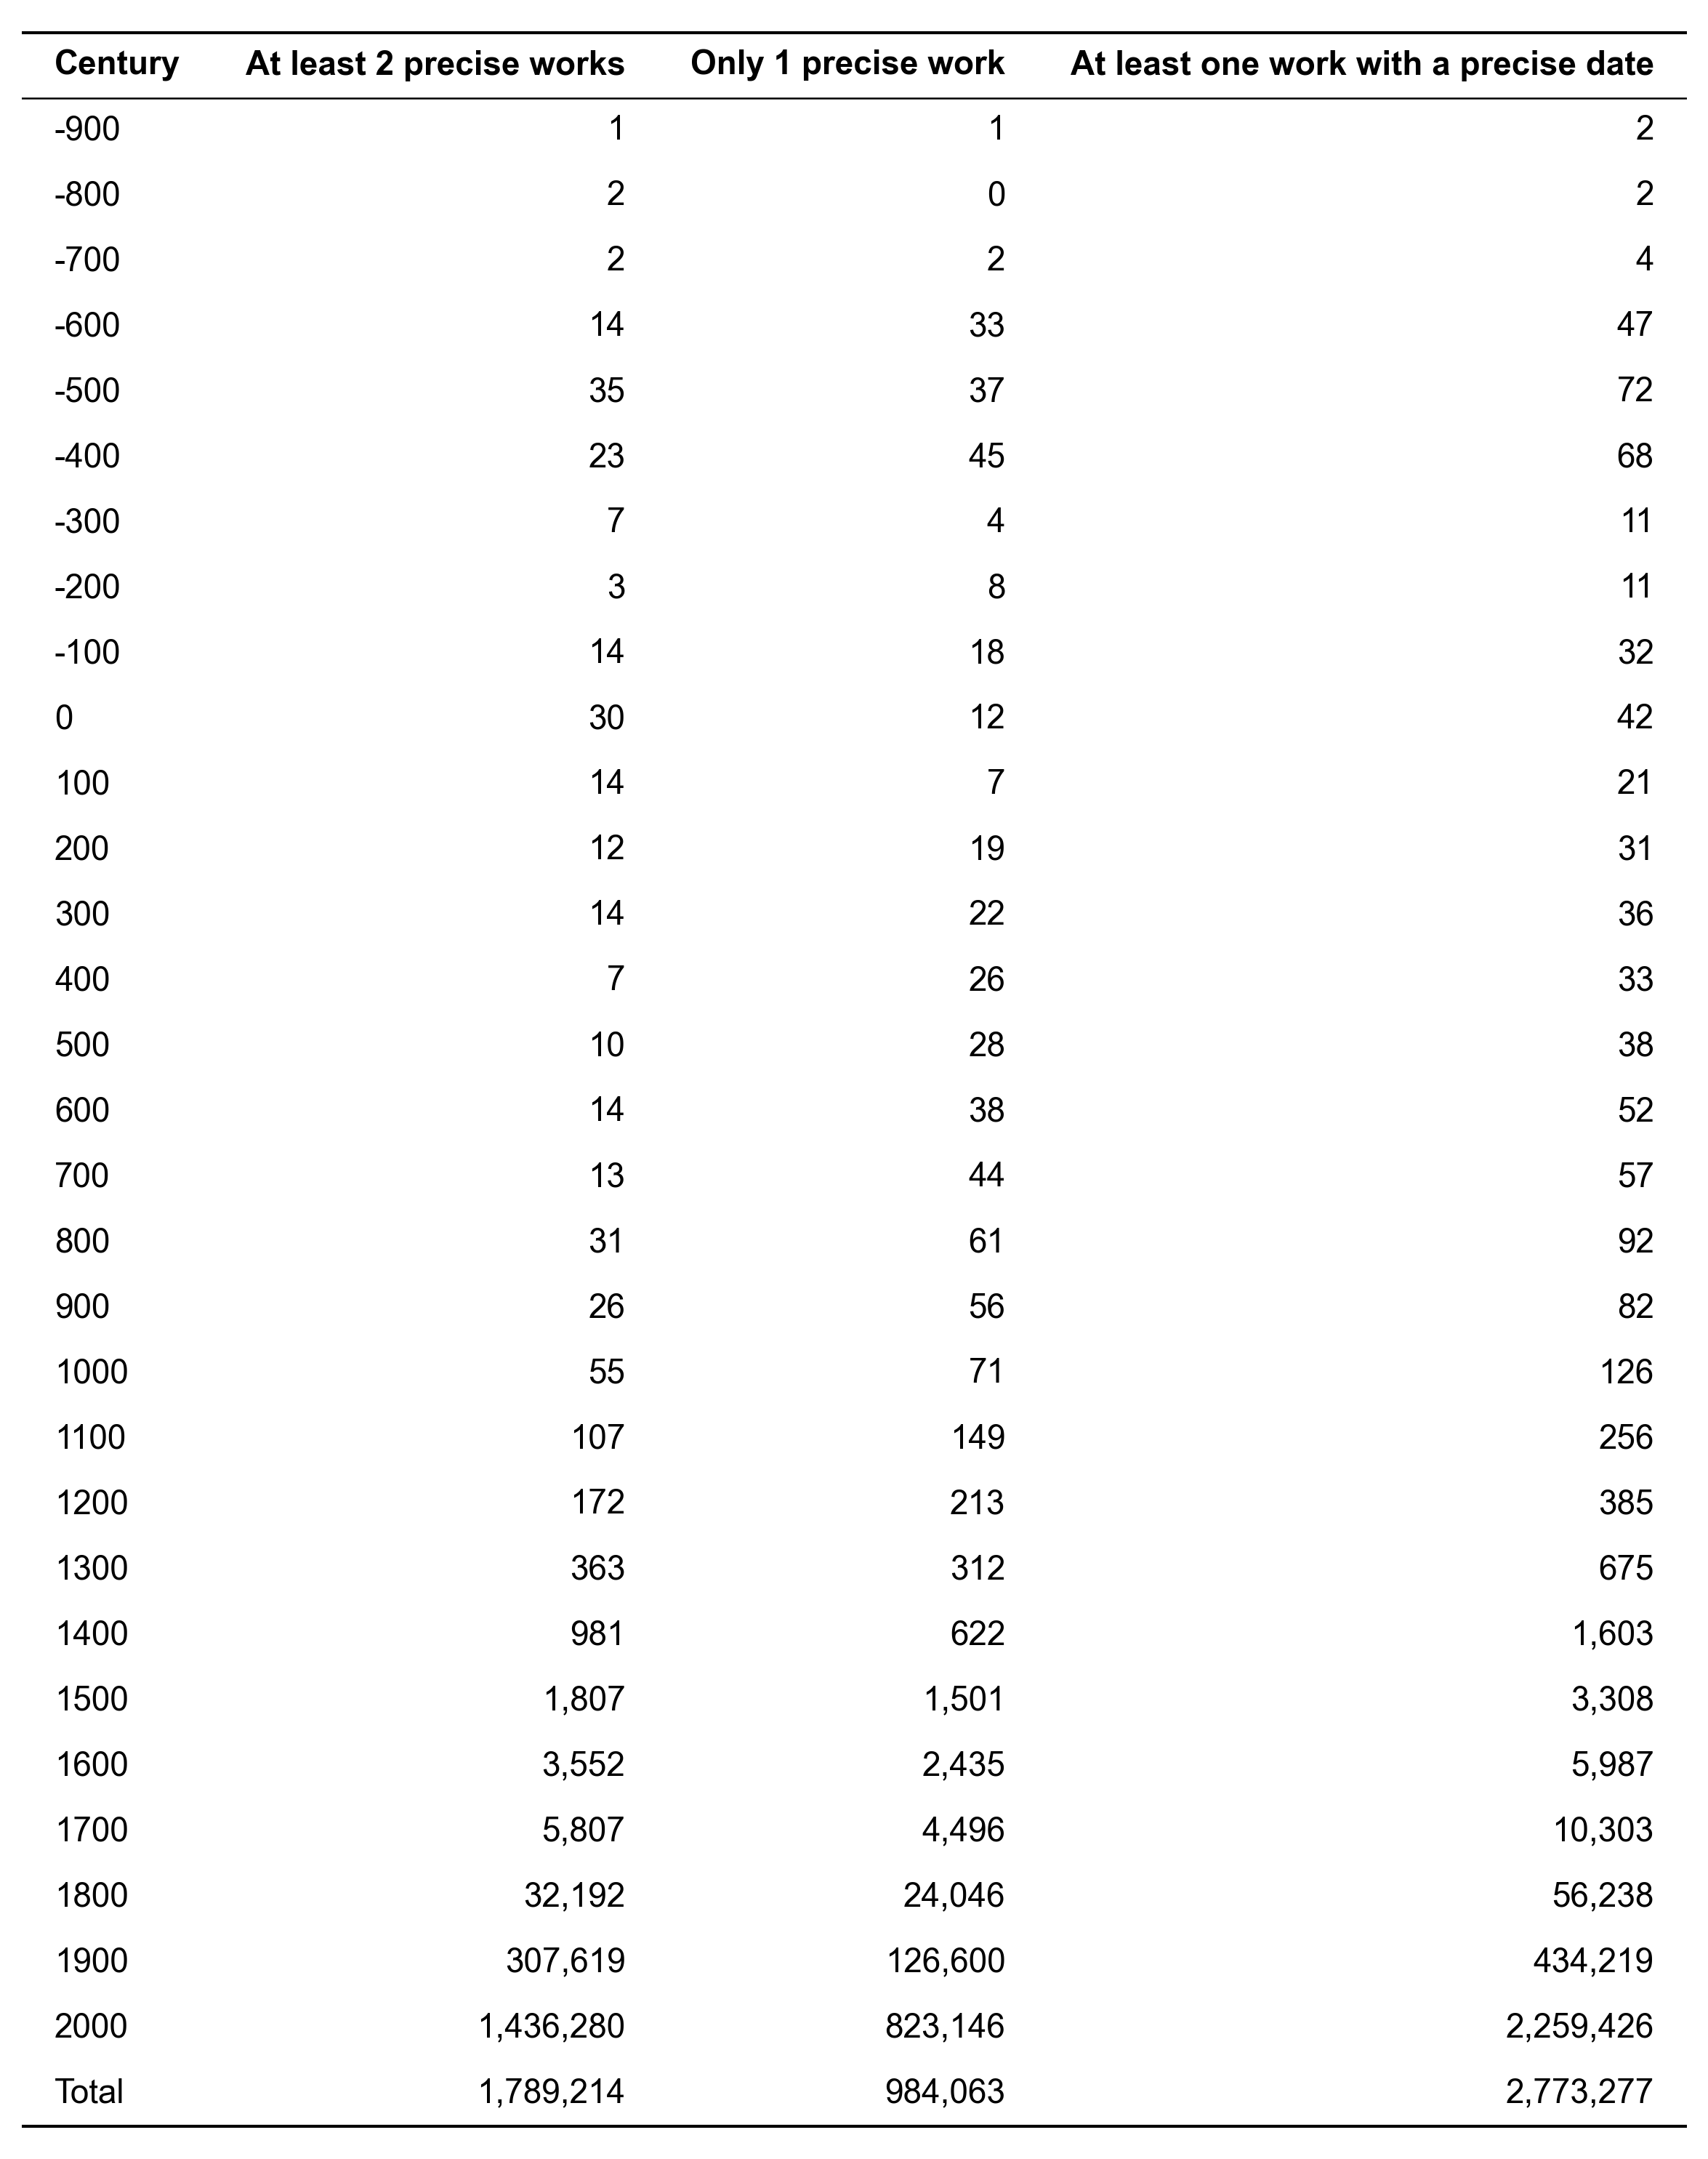

In [26]:
summary = (
    two_precise_century.rename({'individuals': 'At least 2 precise works'})
    .join(one_work_century.rename({'individuals': 'Only 1 precise work'}), on='century_start', how='full', coalesce=True)
    .join(one_or_more_century.rename({'individuals': 'At least one work with a precise date'}), on='century_start', how='full', coalesce=True)
    .fill_null(0)
    .sort('century_start')
    .with_columns(pl.col('century_start').cast(pl.String))
    .rename({'century_start': 'Century'})
)
total_row = pl.DataFrame({
    'Century': ['Total'],
    'At least 2 precise works': [two_precise.height],
    'Only 1 precise work': [one_work.height],
    'At least one work with a precise date': [two_precise.height + one_work.height],
})
show_table(pl.concat([summary, total_row], how='vertical_relaxed'))

### Table: works with a precise inception or publication date, before and after 1500
Over every work in the database; for works with both dates, placed by the earlier one.

17,050,395 works in the database


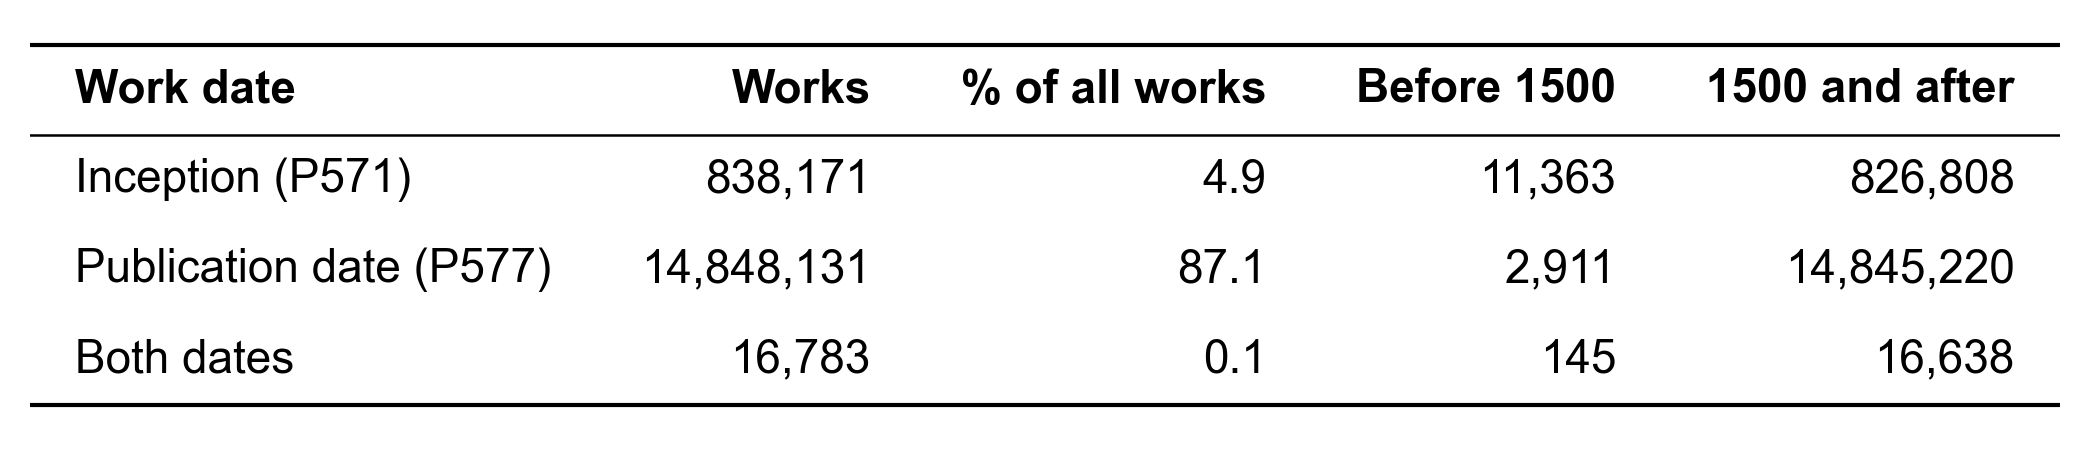

In [27]:
work_counts = connection.execute('''
    WITH dates AS (
        SELECT CASE WHEN inception.precision IN ('day', 'month', 'year', 'decade') THEN inception.year END AS inception_year,
               CASE WHEN publication_date.precision IN ('day', 'month', 'year', 'decade') THEN publication_date.year END AS publication_year
        FROM work
    )
    SELECT 'Inception (P571)' AS date,
           count(inception_year) AS works,
           count(*) FILTER (WHERE inception_year < 1500) AS before_1500,
           count(*) FILTER (WHERE inception_year >= 1500) AS from_1500
    FROM dates
    UNION ALL
    SELECT 'Publication date (P577)',
           count(publication_year),
           count(*) FILTER (WHERE publication_year < 1500),
           count(*) FILTER (WHERE publication_year >= 1500)
    FROM dates
    UNION ALL
    SELECT 'Both dates',
           count(*) FILTER (WHERE inception_year IS NOT NULL AND publication_year IS NOT NULL),
           count(*) FILTER (WHERE least(inception_year, publication_year) < 1500 AND inception_year IS NOT NULL AND publication_year IS NOT NULL),
           count(*) FILTER (WHERE least(inception_year, publication_year) >= 1500 AND inception_year IS NOT NULL AND publication_year IS NOT NULL)
    FROM dates
''').pl()
total_works = connection.execute('SELECT count(*) FROM work').fetchone()[0]
assert (work_counts['works'] == work_counts['before_1500'] + work_counts['from_1500']).all()
print(f'{total_works:,} works in the database')
show_table(work_counts.select(
    pl.col('date').alias('Work date'),
    pl.col('works').alias('Works'),
    (100 * pl.col('works') / total_works).round(1).alias('% of all works'),
    pl.col('before_1500').alias('Before 1500'),
    pl.col('from_1500').alias('1500 and after'),
), decimals=1)

## 5. Ages at first and last work
Individuals with an activity period (2 to 100 years) and a birth year, born from 800 BC to 1899, both ages between 10 and 100. Medians do not add up; means do.

In [28]:
career = spanning.filter(pl.col('birth_year').is_not_null()).with_columns(
    (pl.col('birth_year') // PERIOD_WIDTH * PERIOD_WIDTH).alias('birth_period'),
    (pl.col('first_year') - pl.col('birth_year')).alias('first_age'),
    (pl.col('last_year') - pl.col('birth_year')).alias('last_age'),
)
print(f'{career.height:,} individuals with an activity period and a birth year')
career = career.filter(pl.col('birth_period').is_between(FIRST_PERIOD, LAST_PERIOD) & (pl.col('birth_year') <= LAST_YEAR))
print(f'{career.height:,} born from {FIRST_PERIOD} to {LAST_YEAR}')
career = career.filter(pl.col('first_age').is_between(AGE_MIN, AGE_MAX) & pl.col('last_age').is_between(AGE_MIN, AGE_MAX))
print(f'{career.height:,} with both ages between {AGE_MIN} and {AGE_MAX}: the group used below')
assert abs(career['last_age'].mean() - career['first_age'].mean() - career['span'].mean()) < 1e-9
print(f"Means add up: {career['first_age'].mean():.1f} + {career['span'].mean():.1f} = {career['last_age'].mean():.1f}")

311,583 individuals with an activity period and a birth year
56,291 born from -800 to 1899
55,352 with both ages between 10 and 100: the group used below
Means add up: 34.5 + 20.7 = 55.2


### Age at first work, all individuals and by meta occupation
#### Data plotted

In [29]:
group_stats(career, 'first_age')

meta_occupation,individuals,low,median,high,mean
str,u32,f64,f64,f64,f64
"""All""",55352,26.0,33.0,41.0,34.5
"""Culture""",38696,25.0,31.0,39.0,32.8
"""Discovery/Science""",13029,29.0,36.0,44.0,37.6
"""Leadership""",2232,32.0,40.0,49.0,41.3
"""Sports/Games""",83,30.0,37.0,48.5,39.6
"""Other""",1312,31.0,38.0,48.0,40.1


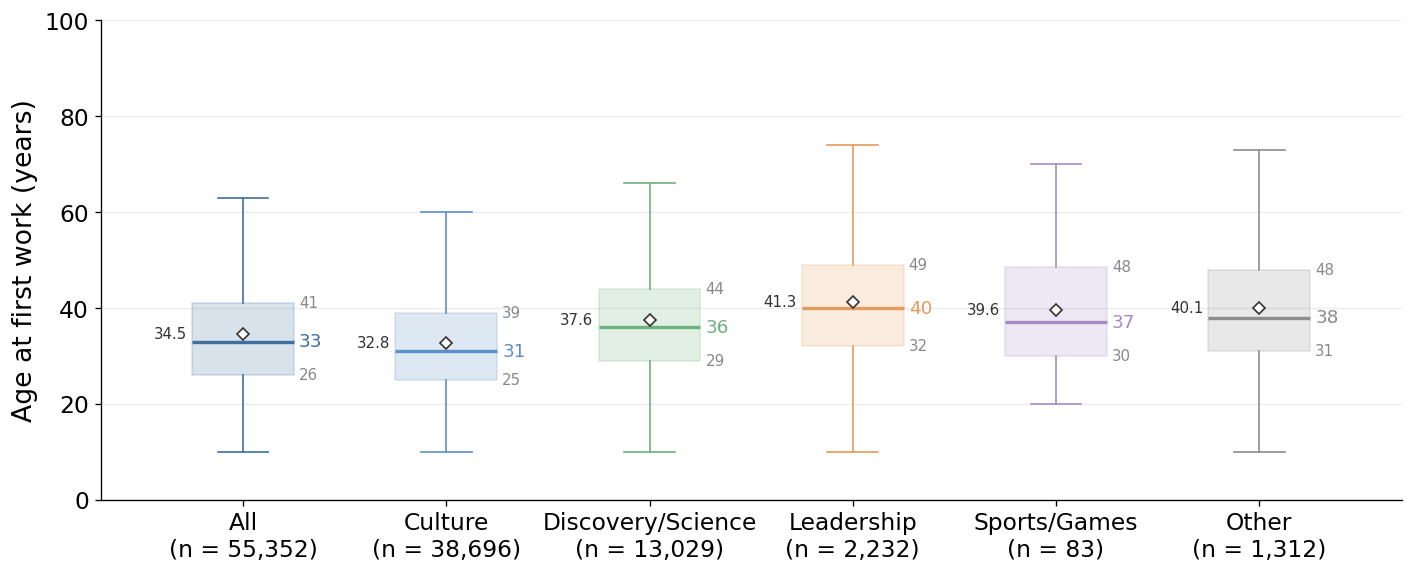

In [30]:
figure_groups(career, 'first_age')

### Age at first work per two-century birth period
#### Data plotted

In [31]:
period_stats = box_stats(career, 'first_age', 'birth_period')
print(f"{period_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} periods with fewer than {MIN_INDIVIDUALS} individuals left out")
period_stats

1 periods with fewer than 5 individuals left out


birth_period,individuals,low,median,high,mean
i64,u32,f64,f64,f64,f64
-800,1,45.0,45.0,45.0,45.0
-600,11,33.5,38.0,41.0,36.8
-400,6,23.5,32.5,40.75,32.8
-200,8,30.25,36.5,42.25,38.6
0,8,33.5,42.5,46.5,41.0
200,9,31.0,36.0,44.0,38.4
400,7,26.0,32.0,52.5,39.1
600,17,35.0,41.0,45.0,43.4
800,14,32.25,38.5,43.5,38.0


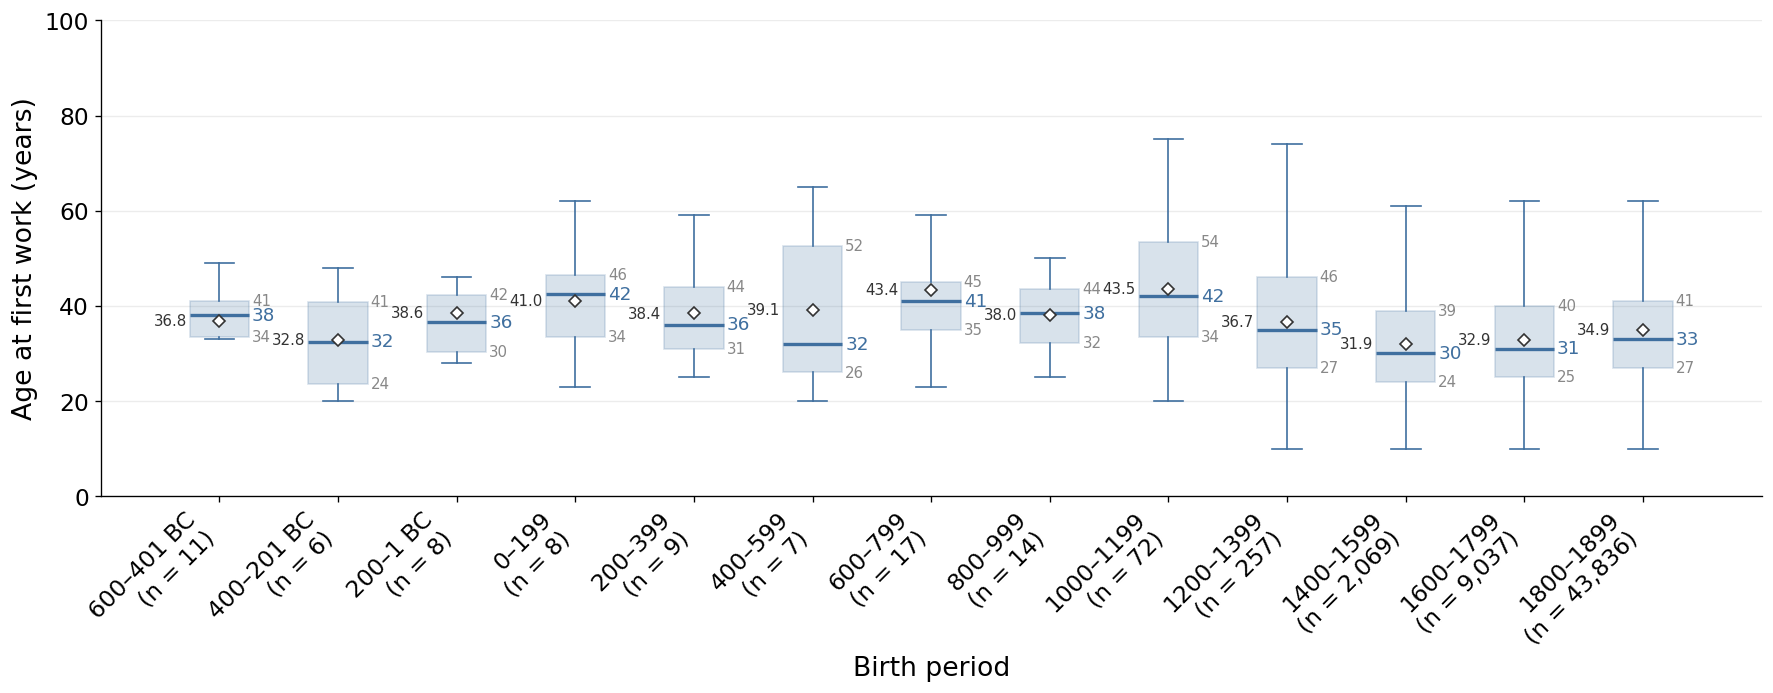

In [32]:
figure_periods(career, 'first_age', 'birth_period', PERIOD_WIDTH, 'Birth period')

### Age at first work per two-century birth period, by meta occupation
Means in the table only (diamonds in the figure).
#### Data plotted

In [33]:
box_stats(career.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), 'first_age', ['meta_occupation', 'birth_period'])

meta_occupation,birth_period,individuals,low,median,high,mean
str,i64,u32,f64,f64,f64,f64
"""Culture""",-800,1,45.0,45.0,45.0,45.0
"""Culture""",-600,9,33.0,38.0,43.0,36.9
"""Culture""",-400,3,22.5,25.0,32.5,28.3
"""Culture""",-200,5,28.0,39.0,46.0,40.6
"""Culture""",0,1,35.0,35.0,35.0,35.0
"""Culture""",600,6,34.0,40.5,44.75,42.3
"""Culture""",800,5,30.0,33.0,40.0,35.4
"""Culture""",1000,37,30.0,40.0,49.0,40.5
"""Culture""",1200,181,25.0,32.0,41.0,34.5


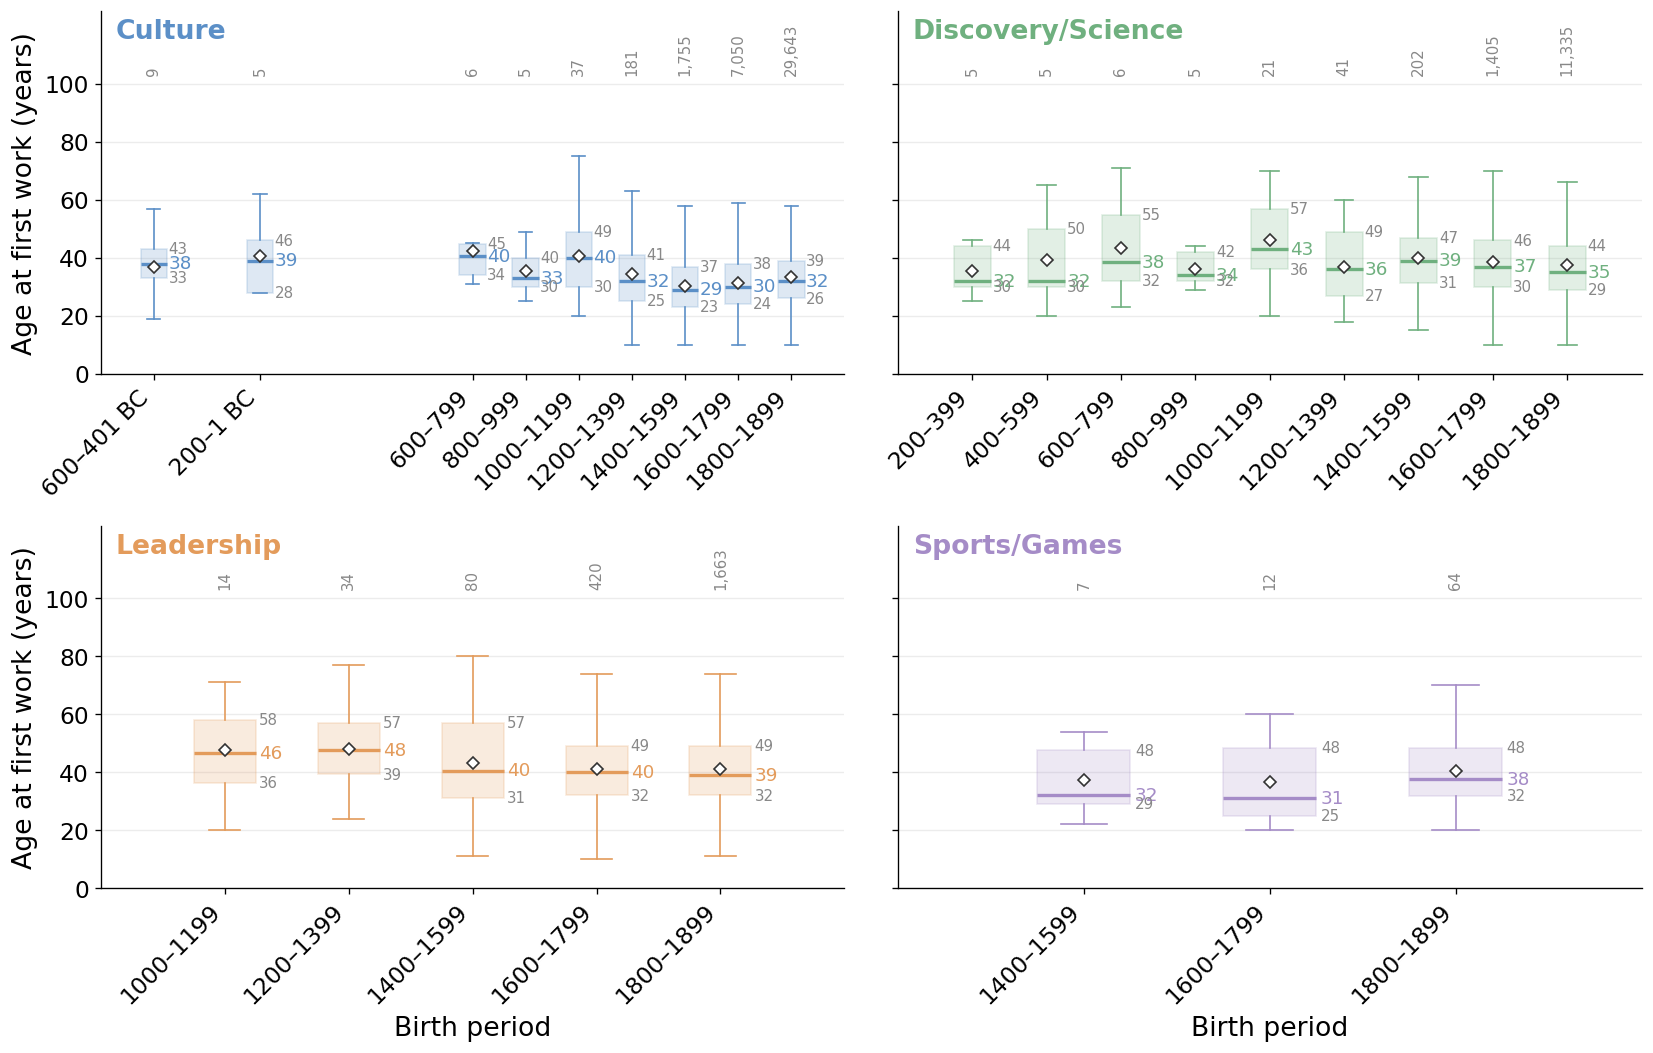

In [34]:
figure_occupation_periods(career, 'first_age')

### Age at last work, all individuals and by meta occupation
#### Data plotted

In [35]:
group_stats(career, 'last_age')

meta_occupation,individuals,low,median,high,mean
str,u32,f64,f64,f64,f64
"""All""",55352,45.0,55.0,65.0,55.2
"""Culture""",38696,44.0,54.0,64.0,54.1
"""Discovery/Science""",13029,48.0,58.0,68.0,58.3
"""Leadership""",2232,46.0,57.0,67.0,56.7
"""Sports/Games""",83,46.0,56.0,65.5,55.1
"""Other""",1312,45.0,55.0,65.0,55.1


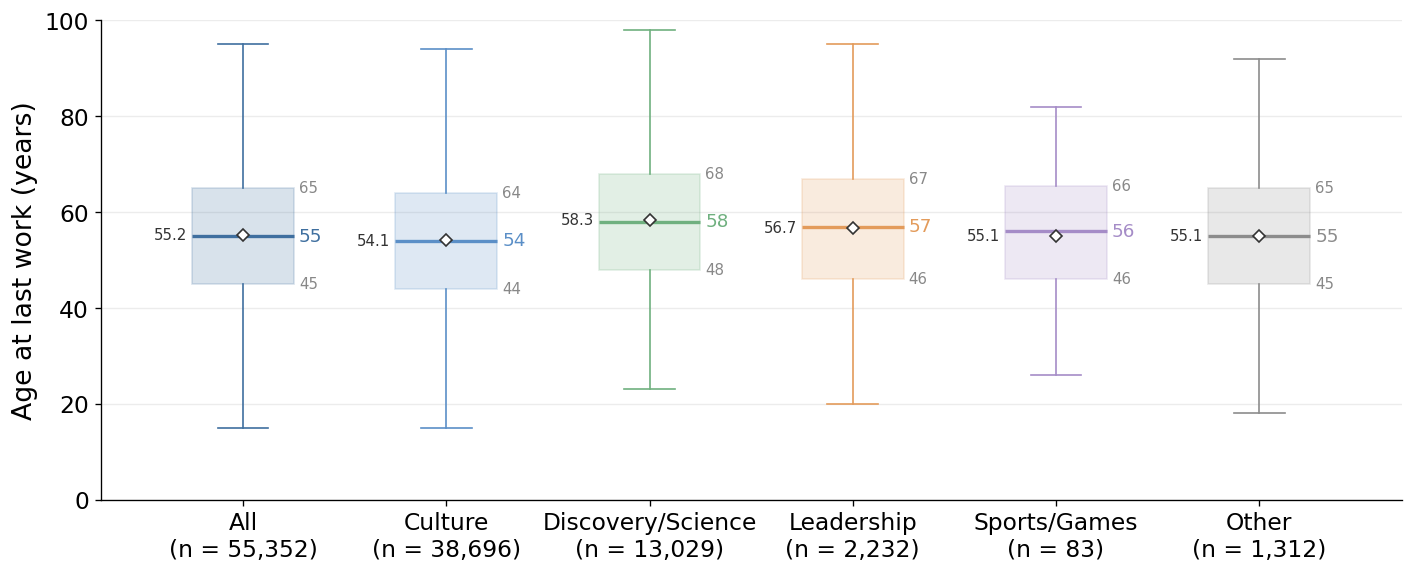

In [36]:
figure_groups(career, 'last_age')

### Age at last work per two-century birth period
#### Data plotted

In [37]:
period_stats = box_stats(career, 'last_age', 'birth_period')
print(f"{period_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} periods with fewer than {MIN_INDIVIDUALS} individuals left out")
period_stats

1 periods with fewer than 5 individuals left out


birth_period,individuals,low,median,high,mean
i64,u32,f64,f64,f64,f64
-800,1,49.0,49.0,49.0,49.0
-600,11,57.5,64.0,73.0,63.5
-400,6,62.25,63.5,64.75,64.3
-200,8,49.0,53.0,57.75,52.6
0,8,53.5,60.0,62.25,55.2
200,9,48.0,55.0,58.0,53.0
400,7,53.0,60.0,71.5,61.6
600,17,54.0,60.0,67.0,60.1
800,14,47.5,54.0,64.5,57.1


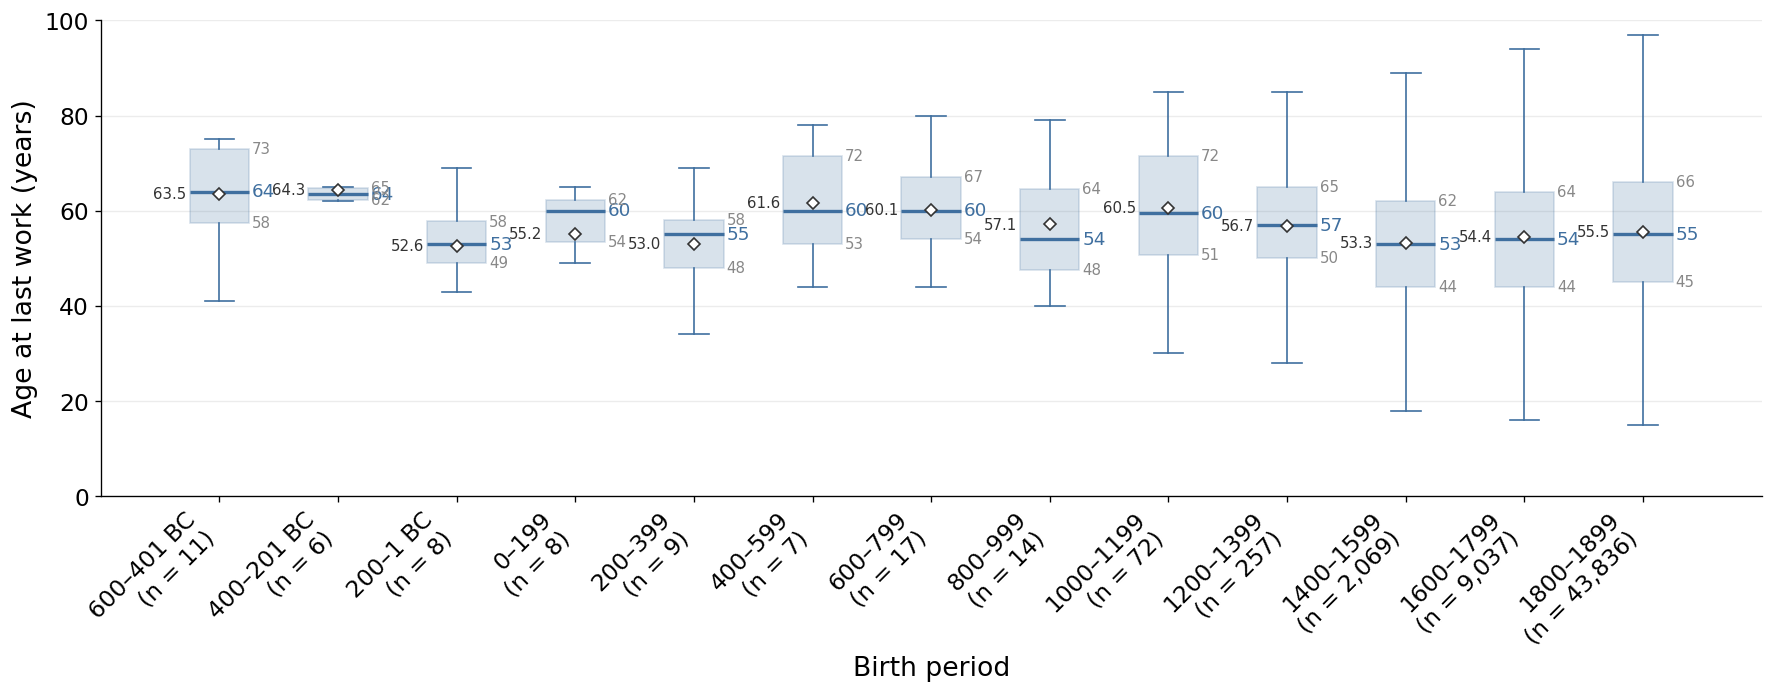

In [38]:
figure_periods(career, 'last_age', 'birth_period', PERIOD_WIDTH, 'Birth period')

### Age at last work per two-century birth period, by meta occupation
Means in the table only (diamonds in the figure).
#### Data plotted

In [39]:
box_stats(career.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), 'last_age', ['meta_occupation', 'birth_period'])

meta_occupation,birth_period,individuals,low,median,high,mean
str,i64,u32,f64,f64,f64,f64
"""Culture""",-800,1,49.0,49.0,49.0,49.0
"""Culture""",-600,9,58.0,64.0,73.0,64.8
"""Culture""",-400,3,59.0,64.0,64.5,61.0
"""Culture""",-200,5,51.0,55.0,56.0,52.8
"""Culture""",0,1,60.0,60.0,60.0,60.0
"""Culture""",600,6,47.25,55.0,59.75,56.0
"""Culture""",800,5,47.0,52.0,63.0,57.2
"""Culture""",1000,37,49.0,56.0,64.0,57.5
"""Culture""",1200,181,50.0,56.0,64.0,56.1


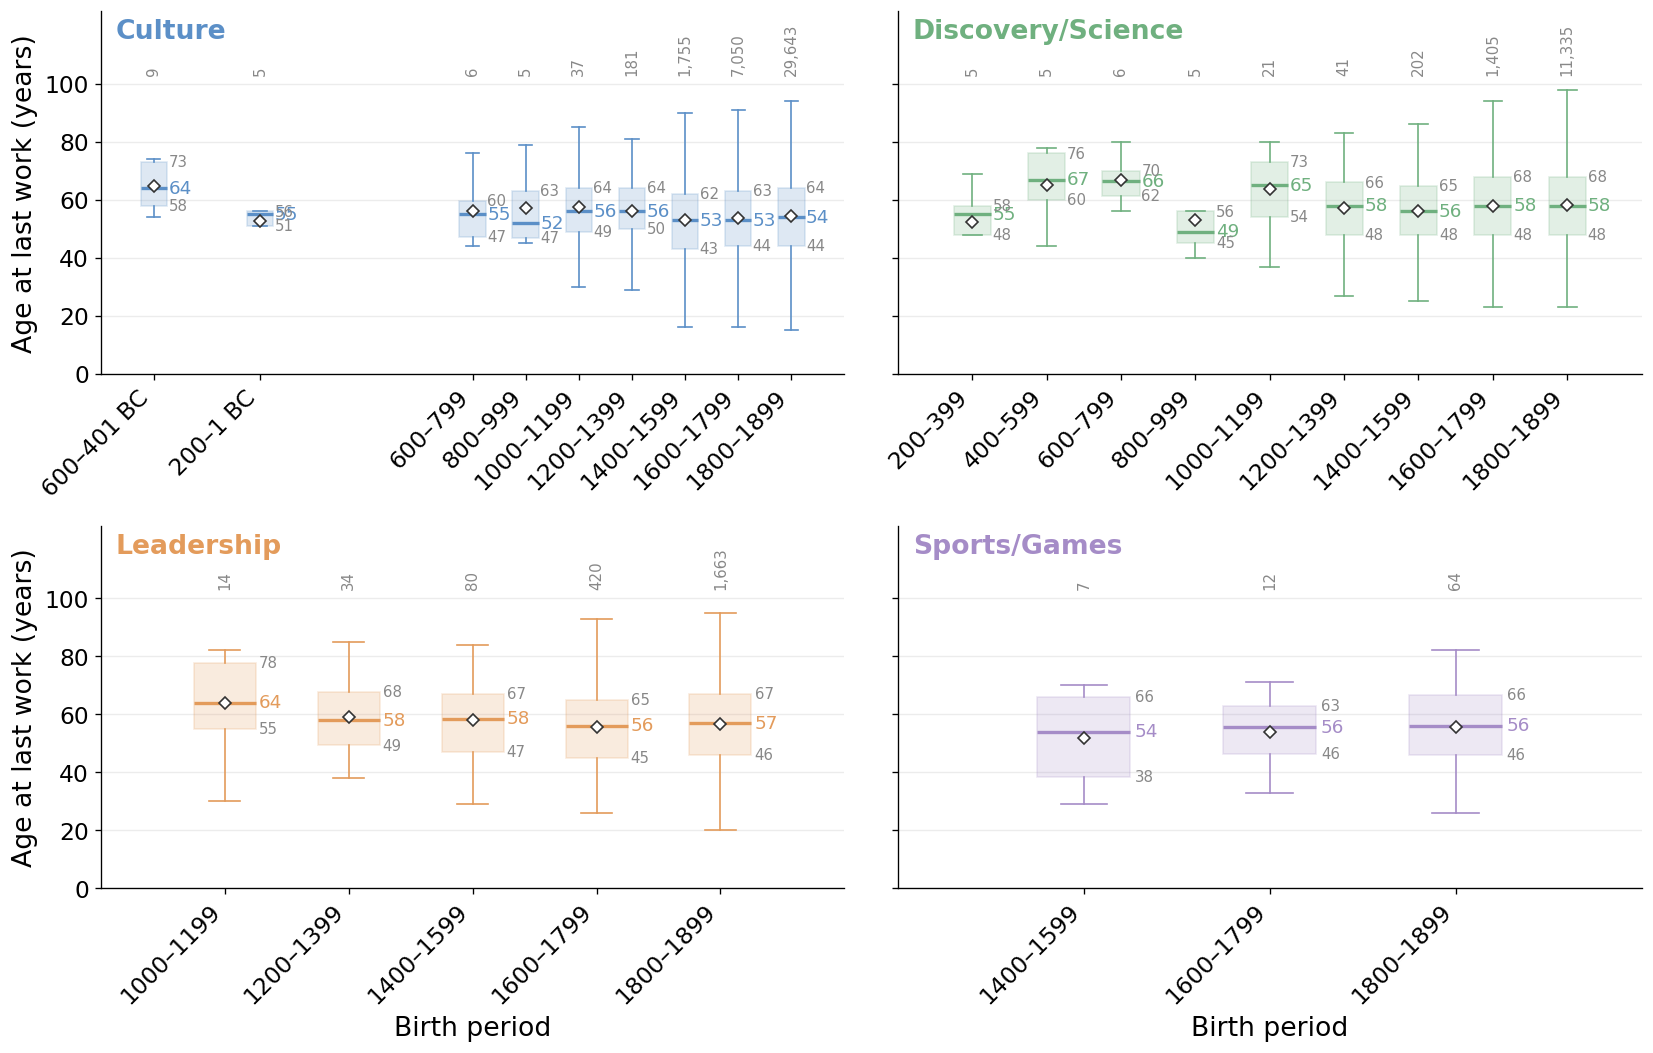

In [40]:
figure_occupation_periods(career, 'last_age')

### Length of activity, all individuals and by meta occupation
#### Data plotted

In [41]:
group_stats(career, 'span')

meta_occupation,individuals,low,median,high,mean
str,u32,f64,f64,f64,f64
"""All""",55352,9.0,18.0,30.0,20.7
"""Culture""",38696,9.0,18.0,31.0,21.3
"""Discovery/Science""",13029,9.0,18.0,30.0,20.7
"""Leadership""",2232,5.0,12.0,23.0,15.4
"""Sports/Games""",83,5.5,13.0,23.5,15.5
"""Other""",1312,5.0,12.0,22.0,15.0


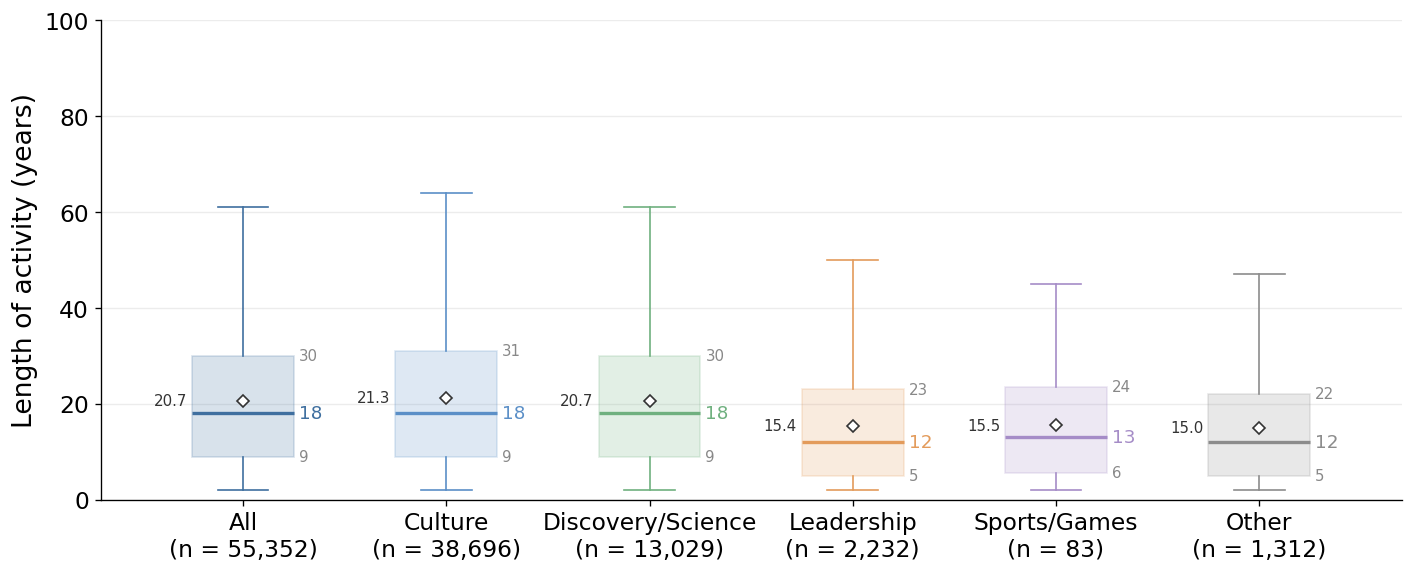

In [42]:
figure_groups(career, 'span')

### Length of activity per two-century birth period
#### Data plotted

In [43]:
period_stats = box_stats(career, 'span', 'birth_period')
print(f"{period_stats.filter(pl.col('individuals') < MIN_INDIVIDUALS).height} periods with fewer than {MIN_INDIVIDUALS} individuals left out")
period_stats

1 periods with fewer than 5 individuals left out


birth_period,individuals,low,median,high,mean
i64,u32,f64,f64,f64,f64
-800,1,4.0,4.0,4.0,4.0
-600,11,17.0,25.0,36.5,26.7
-400,6,23.25,35.0,40.0,31.5
-200,8,8.5,10.0,15.75,14.0
0,8,4.75,11.5,23.5,14.2
200,9,7.0,14.0,18.0,14.6
400,7,10.5,24.0,30.5,22.4
600,17,9.0,13.0,26.0,16.8
800,14,8.25,11.5,27.75,19.1


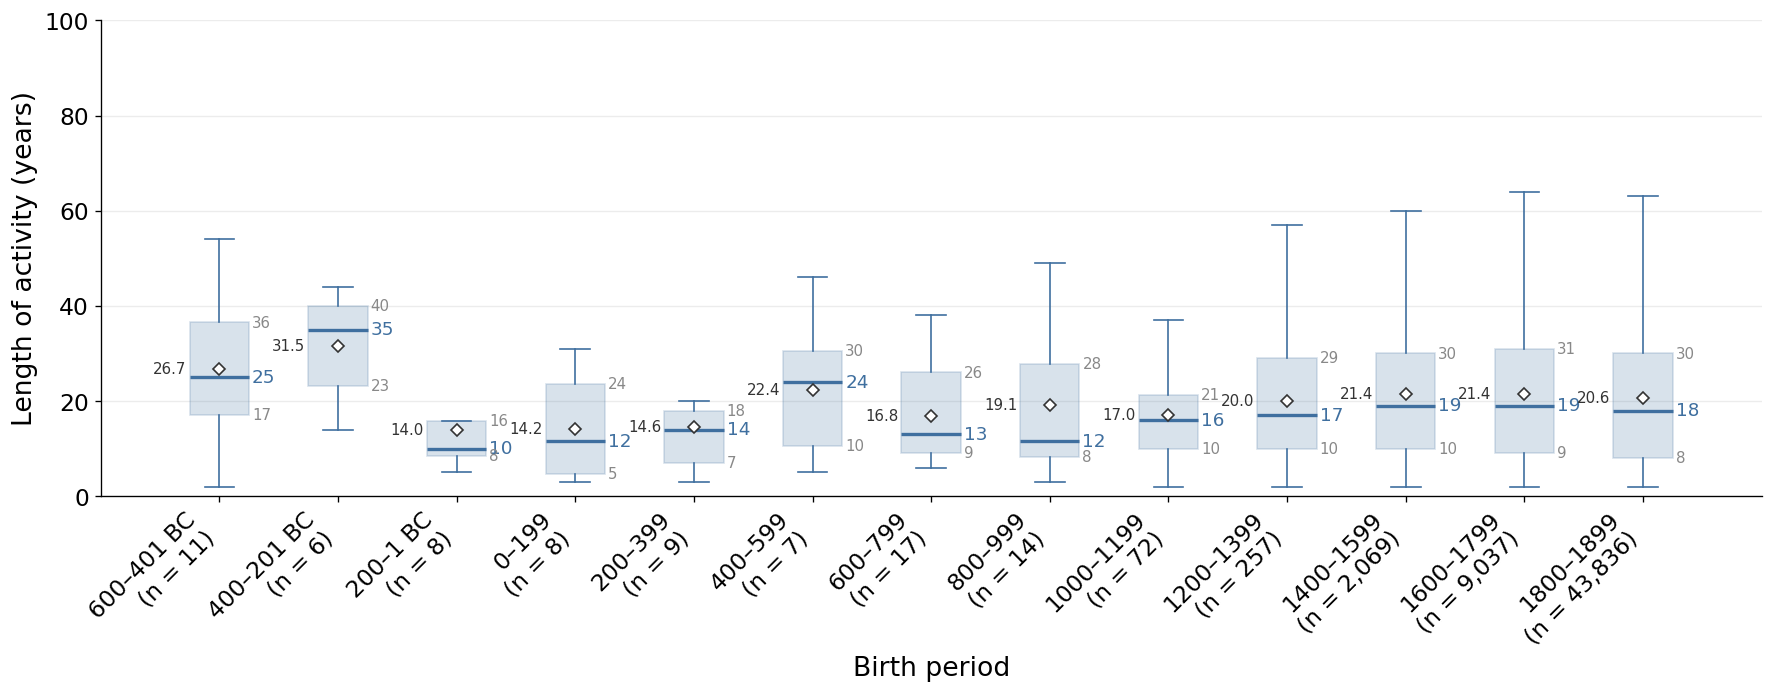

In [44]:
figure_periods(career, 'span', 'birth_period', PERIOD_WIDTH, 'Birth period')

### Length of activity per two-century birth period, by meta occupation
Means in the table only (diamonds in the figure).
#### Data plotted

In [45]:
box_stats(career.filter(pl.col('meta_occupation').is_in(list(OCCUPATION_COLORS))), 'span', ['meta_occupation', 'birth_period'])

meta_occupation,birth_period,individuals,low,median,high,mean
str,i64,u32,f64,f64,f64,f64
"""Culture""",-800,1,4.0,4.0,4.0,4.0
"""Culture""",-600,9,20.0,25.0,35.0,27.9
"""Culture""",-400,3,27.0,40.0,42.0,32.7
"""Culture""",-200,5,7.0,10.0,12.0,12.2
"""Culture""",0,1,25.0,25.0,25.0,25.0
"""Culture""",600,6,8.25,12.5,14.5,13.7
"""Culture""",800,5,5.0,22.0,30.0,21.8
"""Culture""",1000,37,8.0,14.0,20.0,17.0
"""Culture""",1200,181,12.0,20.0,29.0,21.7


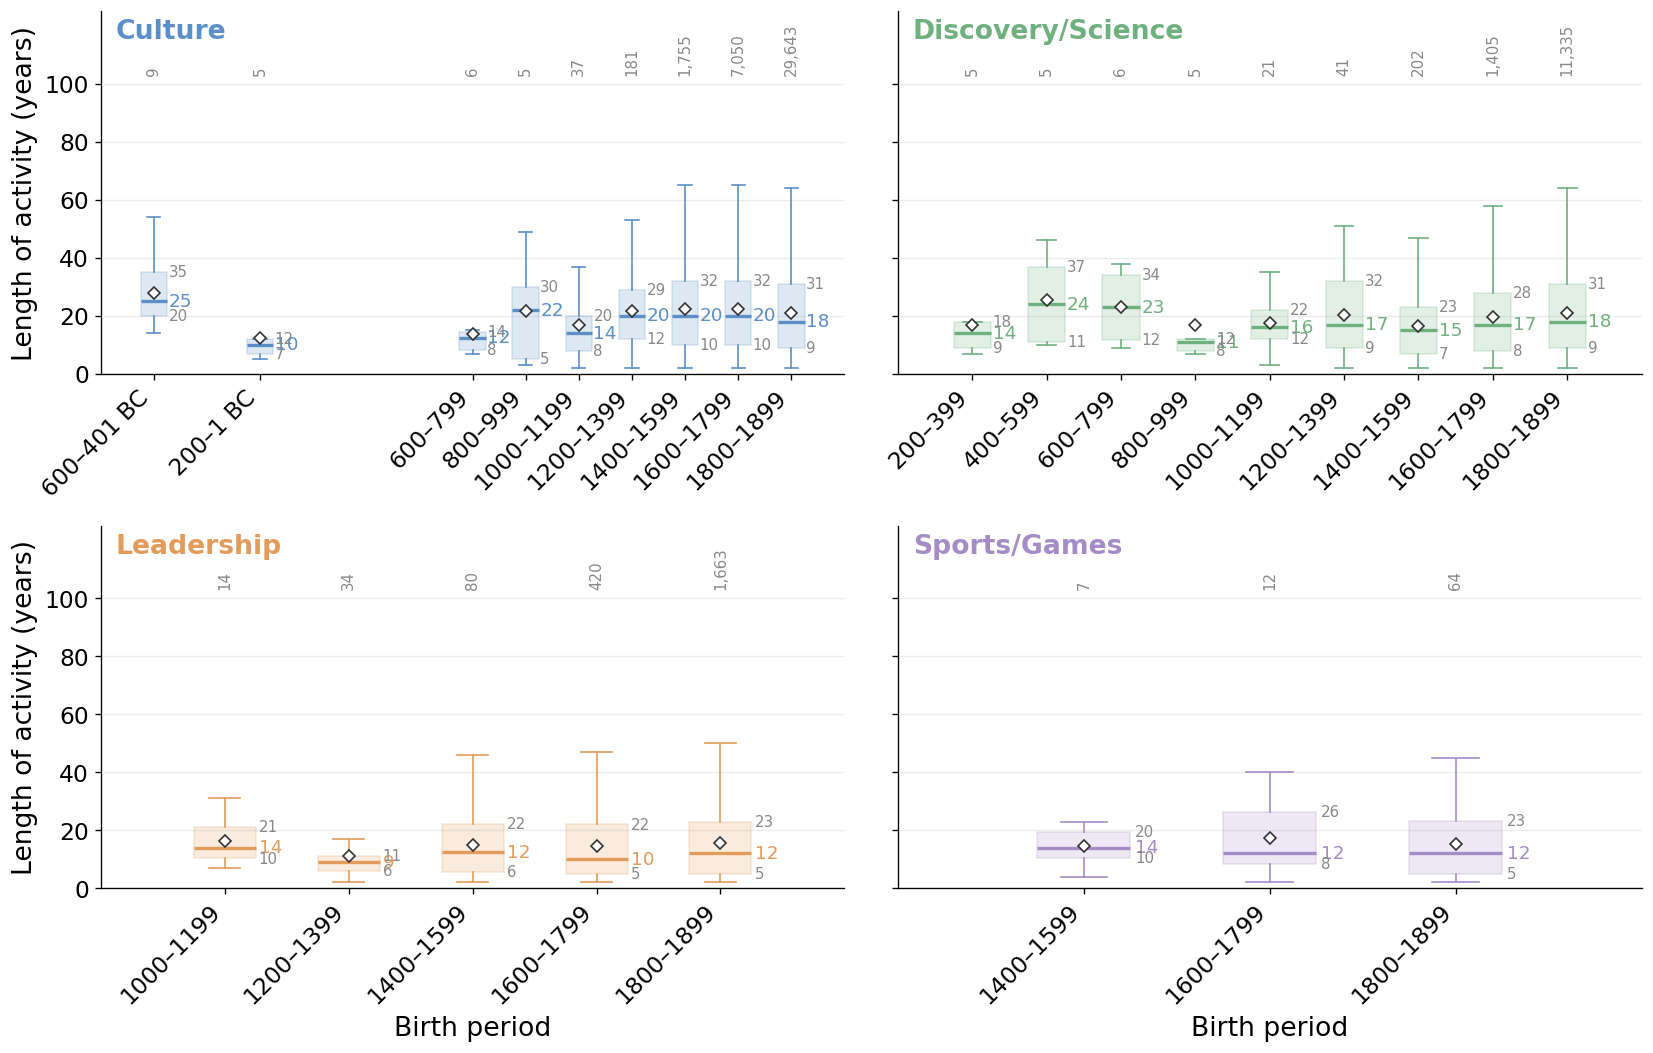

In [46]:
figure_occupation_periods(career, 'span')